# Аналитика маркетплейса: метрики, юнит-экономика и A/B-тест

Комплексное исследование продуктовых метрик маркетплейса, эффективности каналов привлечения и эксперимента с бонусом за первую покупку.


## Вводные по кейсу


# Описание данных

Таблица `Users`

| Поле              | Описание                                       |
|-------------------|------------------------------------------------|
| `user_id`         | Уникальный идентификатор пользователя.         |
| `registration_date` | Дата регистрации пользователя.                |
| `age`             | Возраст пользователя.                          |
| `gender`          | Пол.                                |
| `region`          | Регион.                                        |
| `acq_channel`     | Канал привлечения.                             |
| `buyer_segment`   | Сегмент покупателя.                            |
| `cohort_week`     | Неделя привлечения.|
| `cohort_month`    | Месяц привлечения. |

---

Таблица `Events`

| Поле          | Описание                                                                 |
|---------------|--------------------------------------------------------------------------|
| `event_id`    | Уникальный идентификатор события.                                        |
| `user_id`     | Идентификатор пользователя.                                              |
| `event_date`  | Дата события.                                                            |
| `event_type`  | Тип события.   |
| `os`          | Операционная система.               |
| `device`      | Тип устройства.                                |
| `product_name`| Наименование товара, к которому относится событие (если применимо).      |
| `event_week`  | Неделя события.                                          |
| `event_month` | Месяц события .                                           |

---

Таблица `Orders`

| Поле          | Описание                                                                 |
|---------------|--------------------------------------------------------------------------|
| `order_id`    | Уникальный идентификатор заказа.                                         |
| `user_id`     | Идентификатор пользователя, который сделал заказ |
| `order_date`  | Дата и время оформления заказа.                                          |
| `product_name`| Наименование товара.                                                     |
| `quantity`    | Количество единиц товара в заказе.                                       |
| `unit_price`  | Цена за одну единицу товара.                                             |
| `total_price` | Итоговая сумма заказа.                                                   |
| `category_name` | Наименование категории товара.                                         |
| `order_week`  | Неделя заказа.                                           |
| `order_month` | Месяц заказа.                                            |


Таблица `Campaign_costs`

| Поле         | Описание                                                                 |
|--------------|--------------------------------------------------------------------------|
| `acq_channel`| Канал привлечения.  |
| `spend_month`| Месяц, в который был потрачен бюджет (отражает период, в котором были привлечены пользователи)                      |
| `budget`     | Маркетинговый бюджет (в денежном выражении), потраченный на данный канал в указанном месяце.                           |


## Описание событий


| Событие             | Описание                                                                                  |
|---------------------|-------------------------------------------------------------------------------------------|
| `page_view`         | Открытие любой страницы сайта или приложения пользователем.                                |
| `product_view`      | Просмотр страницы конкретного товара.                                                     |
| `product_click`     | Клик по товару (например, из списка товаров или на баннере).                              |
| `add_to_cart`       | Добавление товара в корзину.                                                              |
| `remove_from_cart`  | Удаление товара из корзины.                                                               |
| `search`            | Выполнение поиска по сайту или приложению.                                                |
| `filter_apply`      | Применение фильтра (например, по цене, бренду, категории).                                |
| `checkout_start`    | Начало оформления заказа (переход к оформлению корзины).                                  |
| `checkout_complete` | Завершение оформления заказа (не гарантирует покупку, покупка зависит от факта оплаты).                                          |
| `user_login`        | Вход пользователя в личный кабинет или аккаунт.                                           |
| `user_logout`       | Выход пользователя из аккаунта.                                                           |
| `wishlist_add`      | Добавление товара в список желаемого (wishlist).                                          |
| `category_view`     | Просмотр страницы категории товаров.                                                      |
| `banner_click`      | Клик по рекламному баннеру на сайте или в приложении.                                     |
| `promo_view`        | Просмотр промо-акции или специального предложения.                                        |


Выручка маркетплейса = 5% от total_price


# Блок кода и расчета метрик


## 2. Первичный анализ и предобработка данных


In [ ]:
import pandas as pd
# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors


In [ ]:
pa_marketplace_orders = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_orders.csv', parse_dates=['order_date','order_week', 'order_month'])
pa_marketplace_campaign_costs = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_campaign_costs.csv', parse_dates=['spend_month'])
pa_marketplace_users = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_users.csv', parse_dates=['registration_date','cohort_week', 'cohort_month'])
pa_marketplace_events = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_events.csv', parse_dates=['event_date','event_week', 'event_month'])


### 2.1. Обзор данных


In [3]:
# Проверяем уникальные значения в столбцах
cat_dict ={'orders': pa_marketplace_orders[['product_name', 'category_name']],
'users': pa_marketplace_users[['region', 'acq_channel', 'buyer_segment']],
'events': pa_marketplace_events[['event_type', 'os', 'device', 'product_name']]}

for name, df in cat_dict.items():
    print(f' Название таблицы {name}')
    for column in df.columns:
        print(f'Название столбца {column}')
        display(df[column].value_counts(normalize=True))
    print()


 Название таблицы orders
Название столбца product_name


Гречка ядрица           0.017093
Рис длиннозерный        0.016615
Масло подсолнечное      0.016264
Макароны                0.016201
Чай черный              0.015977
                          ...   
Штанга олимпийская      0.003476
Запонки классические    0.003380
Кольцо с бриллиантом    0.003380
Чехлы на сиденья        0.003349
Кровать двуспальная     0.003189
Name: product_name, Length: 200, dtype: float64

Название столбца category_name


Продукты питания                   0.128424
Детская одежда                     0.045317
Зоотовары                          0.044520
Книги и канцтовары                 0.041968
Аксессуары для гаджетов            0.040023
Обувь мужская                      0.039959
Одежда для спорта                  0.039800
Товары для кухни                   0.039449
Обувь женская                      0.038620
Женская одежда                     0.037982
Сумки и аксессуары                 0.037631
Средства для ухода                 0.037376
Товары для новорожденных           0.037025
Детские игрушки                    0.036069
Косметика и парфюмерия             0.033709
Декор и освещение                  0.033581
Автотовары                         0.033262
Бытовая техника                    0.032848
Украшения и часы                   0.032656
Мужская одежда                     0.032592
Спортивный инвентарь               0.031891
Инструменты и садовый инвентарь    0.031891
Медицинские товары              


 Название таблицы users
Название столбца region


...

Windows    0.255134
Android    0.251884
iOS        0.248837
macOS      0.244146
Name: os, dtype: float64

Название столбца device


mobile     0.335296
tablet     0.332487
desktop    0.332217
Name: device, dtype: float64

Название столбца product_name


Коврик для йоги         0.005263
Угги зимние             0.005232
Кроссовки для бега      0.005229
Пальто зимнее           0.005221
Макароны                0.005219
                          ...   
Лопата штыковая         0.004762
Ботинки классические    0.004749
Микроволновка           0.004749
Секатор садовый         0.004700
Брюки чино              0.004604
Name: product_name, Length: 200, dtype: float64

In [4]:
tables_dict = {
    'pa_marketplace_orders': pa_marketplace_orders,
    'pa_marketplace_campaign_costs': pa_marketplace_campaign_costs,
    'pa_marketplace_users': pa_marketplace_users,
    'pa_marketplace_events': pa_marketplace_events
}
for name, tables in tables_dict.items():
    print(f'Название таблицы {name}')
    display(tables.head(5))
    tables.info()
    print()


Название таблицы pa_marketplace_orders


,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month
0,1,3,2024-01-19 01:52:52,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
1,2,3,2024-01-19 01:52:52,Молоток слесарный,1,11340.38,11340.38,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
2,3,3,2024-01-19 01:52:52,Секатор садовый,2,10892.09,21784.18,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
3,4,3,2024-01-25 13:59:38,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-22,2024-01-01
4,5,3,2024-01-25 13:59:38,Чай черный,1,2099.59,2099.59,Продукты питания,2024-01-22,2024-01-01


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31357 entries, 0 to 31356
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       31357 non-null  int64         
 1   user_id        31357 non-null  int64         
 2   order_date     31357 non-null  datetime64[ns]
 3   product_name   31357 non-null  object        
 4   quantity       31357 non-null  int64         
 5   unit_price     31357 non-null  float64       
 6   total_price    31357 non-null  float64       
 7   category_name  31357 non-null  object        
 8   order_week     31357 non-null  datetime64[ns]
 9   order_month    31357 non-null  datetime64[ns]
dtypes: datetime64[ns](3), float64(2), int64(3), object(2)
memory usage: 2.4+ MB

Название таблицы pa_marketplace_campaign_costs


,Unnamed: 0,acq_channel,spend_month,budget
0,0,Affiliate,2024-01-01,179343.3875
1,1,Affiliate,2024-02-01,175488.4875
2,2,Affiliate,2024-03-01,164543.4750
3,3,Affiliate,2024-04-01,186869.9750
4,4,Affiliate,2024-05-01,166443.7750


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88 entries, 0 to 87
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Unnamed: 0   88 non-null     int64         
 1   acq_channel  88 non-null     object        
 2   spend_month  88 non-null     datetime64[ns]
 3   budget       88 non-null     float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 2.9+ KB

Название таблицы pa_marketplace_users


,user_id,registration_date,age,gender,region,acq_channel,buyer_segment,cohort_week,cohort_month
0,1,2024-01-01 00:47:00,35,M,Москва,Google Ads,regular,2024-01-01,2024-01-01
1,2,2024-01-01 19:01:00,53,M,Москва,Email Marketing,rare,2024-01-01,2024-01-01
2,3,2024-01-01 04:13:00,66,F,Санкт-Петербург,Google Ads,regular,2024-01-01,2024-01-01
3,4,2024-01-01 17:18:00,58,M,Краснодар,Affiliate,one_time,2024-01-01,2024-01-01
4,5,2024-01-01 08:29:00,58,F,Другие регионы,Google Ads,regular,2024-01-01,2024-01-01


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44151 entries, 0 to 44150
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            44151 non-null  int64         
 1   registration_date  44151 non-null  datetime64[ns]
 2   age                44151 non-null  int64         
 3   gender             44151 non-null  object        
 4   region             44151 non-null  object        
 5   acq_channel        44151 non-null  object        
 6   buyer_segment      44151 non-null  object        
 7   cohort_week        44151 non-null  datetime64[ns]
 8   cohort_month       44151 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int64(2), object(4)
memory usage: 3.0+ MB

Название таблицы pa_marketplace_events


,event_id,user_id,event_date,event_type,os,device,product_name,event_week,event_month
0,3132,100,2024-01-01,page_view,iOS,mobile,NaN,2024-01-01,2024-01-01
1,3133,100,2024-01-01,product_view,iOS,mobile,Шорты для тренировок,2024-01-01,2024-01-01
2,3134,100,2024-01-01,product_click,iOS,mobile,Куртка детская,2024-01-01,2024-01-01
3,3135,100,2024-01-01,add_to_cart,iOS,mobile,Балетки классические,2024-01-01,2024-01-01
4,3136,100,2024-01-01,checkout_start,iOS,mobile,NaN,2024-01-01,2024-01-01


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 785859 entries, 0 to 785858
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   event_id      785859 non-null  int64         
 1   user_id       785859 non-null  int64         
 2   event_date    785859 non-null  datetime64[ns]
 3   event_type    785859 non-null  object        
 4   os            785859 non-null  object        
 5   device        785859 non-null  object        
 6   product_name  385740 non-null  object        
 7   event_week    785859 non-null  datetime64[ns]
 8   event_month   785859 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int64(2), object(4)
memory usage: 54.0+ MB



### 2.2. Обработка данных


In [ ]:
#Удалим столбец без имени в pa_marketplace_campaign_costs
pa_marketplace_campaign_costs = pa_marketplace_campaign_costs.drop('Unnamed: 0', axis=1)


In [6]:
pa_marketplace_events.isna().sum()


event_id             0
user_id              0
event_date           0
event_type           0
os                   0
device               0
product_name    400119
event_week           0
event_month          0
dtype: int64

In [7]:
#Проверяем пропуски в таблице pa_marketplace_event
pa_marketplace_events.groupby('event_type')['product_name'].apply(lambda x: x.isna().sum())


event_type
add_to_cart               0
banner_click          13826
category_view         14040
checkout_complete     84012
checkout_start        92401
filter_apply          14243
page_view            125663
product_click             0
product_view              0
promo_view            13935
remove_from_cart          0
search                13909
user_login            14109
user_logout           13981
wishlist_add              0
Name: product_name, dtype: int64

### 2.3. Проверка качества данных


In [8]:
#Проверяем на полные дубликаты
for name, tables in tables_dict.items():
    print(f'Количество полных дубликатов в таблице {name}:')
    display(tables.duplicated().sum())
    print()


Количество полных дубликатов в таблице pa_marketplace_orders:


0


Количество полных дубликатов в таблице pa_marketplace_campaign_costs:


0


Количество полных дубликатов в таблице pa_marketplace_users:


0


Количество полных дубликатов в таблице pa_marketplace_events:


0

In [9]:
#Проверяем столбцы датафреймов, которые должны содержать уникальные значения id. Количество и дубликаты
display(pa_marketplace_orders['order_id'].nunique(), pa_marketplace_orders['order_id'].duplicated().sum())
display(pa_marketplace_users['user_id'].nunique(), pa_marketplace_users['user_id'].duplicated().sum())
display(pa_marketplace_events['event_id'].nunique(), pa_marketplace_events['event_id'].duplicated().sum())


31357

0

44151

0

785859

0

In [10]:
#Посмотрим временные диапазоны данных
pa_marketplace_events['event_date'].agg({'min':min, 'max':max})


min   2024-01-01
max   2024-12-31
Name: event_date, dtype: datetime64[ns]

In [11]:
pa_marketplace_orders['order_date'].agg({'min':min, 'max':max})


min   2024-01-01 08:03:45
max   2024-12-31 23:00:53
Name: order_date, dtype: datetime64[ns]

In [12]:
pa_marketplace_users['registration_date'].agg({'min':min, 'max':max})


min   2024-01-01 00:07:00
max   2024-12-31 23:44:00
Name: registration_date, dtype: datetime64[ns]

In [13]:
pa_marketplace_campaign_costs['spend_month'].agg({'min':min, 'max':max})


min   2024-01-01
max   2025-01-01
Name: spend_month, dtype: datetime64[ns]

**Выводы:**

1. **Качество данных хорошее.** Полные дубликаты отсутствуют, ID пользователей, заказов и событий уникальны. Временные границы данных корректны и охватывают ровно 2024 год.
2. **Обнаружены и обработаны незначительные аномалии:**
   - Удален технический столбец `Unnamed: 0` из таблицы `campaign_costs`.
   - Пропуски в `product_name` (400 119 записей) в таблице `events` логичны и связаны с типами событий, не подразумевающих товар (`page_view`, `search`, `checkout_start` и т.д.).
3. **Принятые решения:** Данные пригодны для анализа. Аномалии незначительны и не требуют исключения записей.


### 2. Построить обзор ключевых метрик


На этом этапе вам нужно выполнить верхнеуровневую оценку состояния продукта с помощью собранных витрин. Бизнес просит просто оценить текущее состояние — без глубокой сегментации и оценки сложных метрик.

Выручка бизнеса — 5% комиссии от стоимости любой продажи.

Посмотрите на общую динамику ключевых метрик: например, Revenue, ARPU или ARPPU, MAU, WAU, DAU, AOV, Retention, CTR, CR в заказ. Следовать этому списку необязательно, исходите из данных.

Ваша цель — быстро получить целостную картину, не применяя сегментацию и не рассматривая глубокие срезы. Определите, соответствует ли продукт базовым ожиданиям, виден ли рост, есть ли тревожные сигналы.

Результатом задания будет ваш вывод о динамике основных продуктовых метрик.


### 3.1. Метрики активности


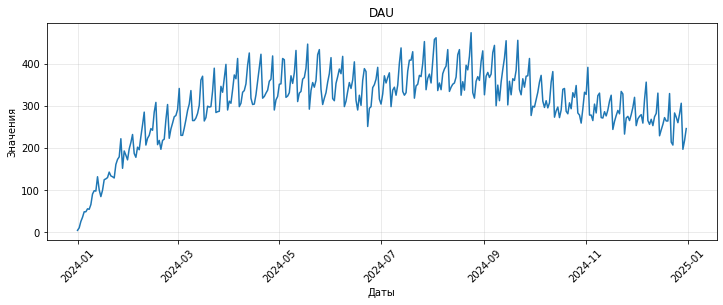

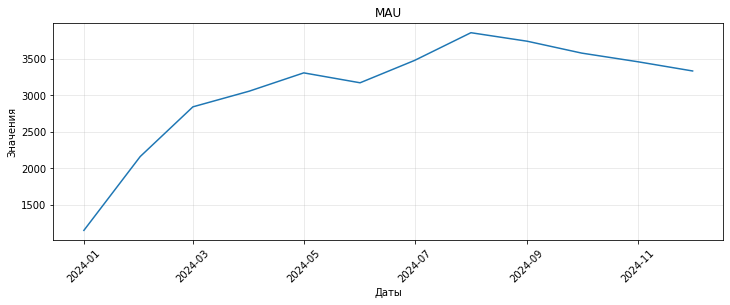

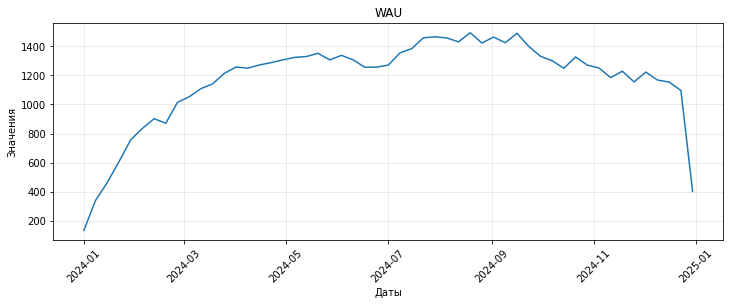

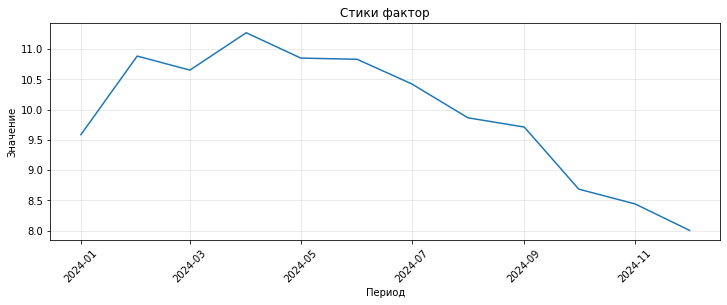

In [14]:
plt.subplots(figsize=(12,4))

#Cчитаем и визуализируем DAU
dau = pa_marketplace_events.groupby('event_date')['user_id'].nunique().reset_index()
plt.plot(dau['event_date'], dau['user_id'])
plt.title('DAU')
plt.xlabel('Даты')
plt.ylabel('Значения')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.show()

#Cчитаем и визуализируем MAU
plt.subplots(figsize=(12,4))
mau = pa_marketplace_events.groupby('event_month')['user_id'].nunique().reset_index()
plt.plot(mau['event_month'], mau['user_id'])
plt.title('MAU')
plt.xlabel('Даты')
plt.ylabel('Значения')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.show() 


#Cчитаем и визуализируем WAU
plt.subplots(figsize=(12,4))
wau = pa_marketplace_events.groupby('event_week')['user_id'].nunique().reset_index()
plt.plot(wau['event_week'], wau['user_id'])
plt.title('WAU')
plt.xlabel('Даты')
plt.ylabel('Значения')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.show() 



#Cчитаем и визуализируем StickyFactor
dau['date'] = pd.to_datetime(dau['event_date'])
dau['month'] = dau['date'].dt.to_period('M').dt.to_timestamp()
dau_monthly_average = dau.groupby('month')['user_id'].mean().astype('float64').reset_index()
stickiness_table = mau.merge(dau_monthly_average,  left_on='event_month', right_on='month', how='left' )
stickiness_table = stickiness_table.rename(columns={'user_id_x': 'mau', 'user_id_y': 'dau_avg'})
stickiness_table['stick'] =100 * (stickiness_table['dau_avg']/stickiness_table['mau'] ) 

plt.subplots(figsize=(12,4))
plt.title('Стики фактор')

plt.xlabel('Период')
plt.ylabel('Значение')
plt.plot(stickiness_table['month'], stickiness_table['stick'])
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.show()


### 3.2. Метрики монетизации (верхний уровень)


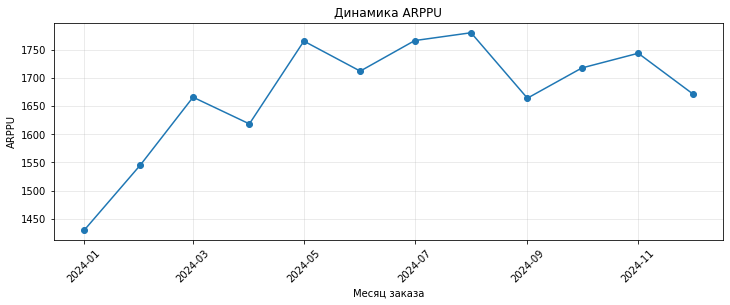

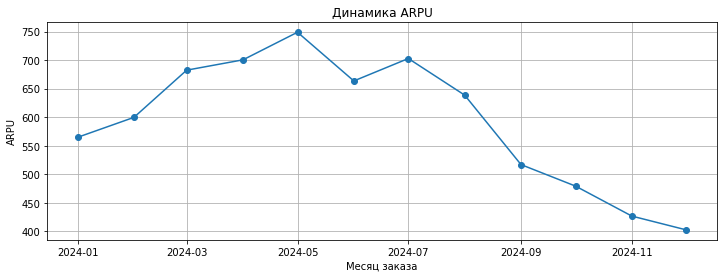

In [15]:
#Считаем выручку
pa_marketplace_orders['revenue'] = pa_marketplace_orders['total_price'] * 0.05

#ARPPU
monthly_paid_stats = pa_marketplace_orders.groupby('order_month').agg(
    total_revenue=('revenue', 'sum'), # Сумма выручки за месяц
    total_price=('total_price', 'sum'), 
    unique_paid_users=('user_id', 'nunique'),# Уникальные пользователи за месяц
    total_orders = ('order_id', 'count') #Количество заказов
).reset_index()
monthly_paid_stats['arppu'] = monthly_paid_stats['total_revenue'] /  monthly_paid_stats['unique_paid_users']
plt.figure(figsize=(12, 4))
plt.plot(monthly_paid_stats['order_month'], monthly_paid_stats['arppu'], marker = 'o')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.title('Динамика ARPPU')
plt.xlabel('Месяц заказа')
plt.ylabel('ARPPU')
plt.show()

#ARPU
arpu_data = pd.merge(monthly_paid_stats, mau, left_on='order_month', right_on='event_month', how='inner')
arpu_data['arpu'] = arpu_data['total_revenue'] / arpu_data['user_id']
plt.figure(figsize=(12, 4))
plt.plot(arpu_data['order_month'], arpu_data['arpu'], marker = 'o')
plt.grid()
plt.title('Динамика ARPU')
plt.xlabel('Месяц заказа')
plt.ylabel('ARPU')
plt.show()


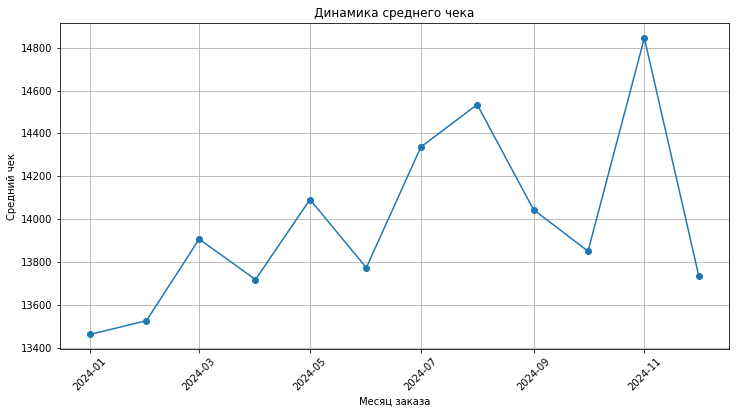

In [16]:
#AOV
monthly_paid_stats['aov'] = monthly_paid_stats['total_price'] /  monthly_paid_stats['total_orders']
plt.figure(figsize=(12, 6))
plt.plot(monthly_paid_stats['order_month'], monthly_paid_stats['aov'], marker = 'o')
plt.title('Динамика среднего чека')
plt.grid()
plt.xticks(rotation=45)
plt.xlabel('Месяц заказа')
plt.ylabel('Средний чек')
plt.show()


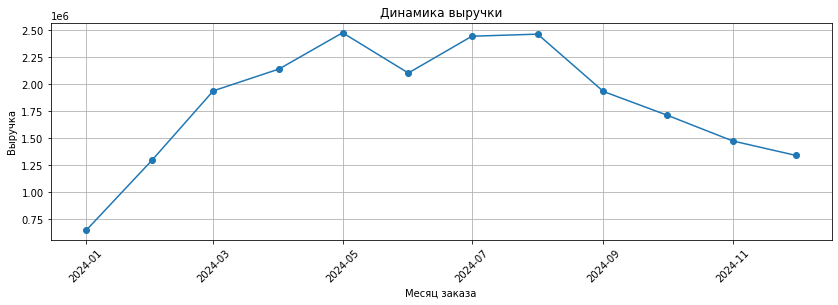

In [17]:
#Считаем и визуализируем динамику revenue по месяцам
plt.figure(figsize=(14, 4))
plt.plot(monthly_paid_stats['order_month'], monthly_paid_stats['total_revenue'], marker = 'o')
plt.grid()
plt.xticks(rotation=45)
plt.title('Динамика выручки')
plt.xlabel('Месяц заказа')
plt.ylabel('Выручка')
plt.show()



### 3.3. Метрики конверсии


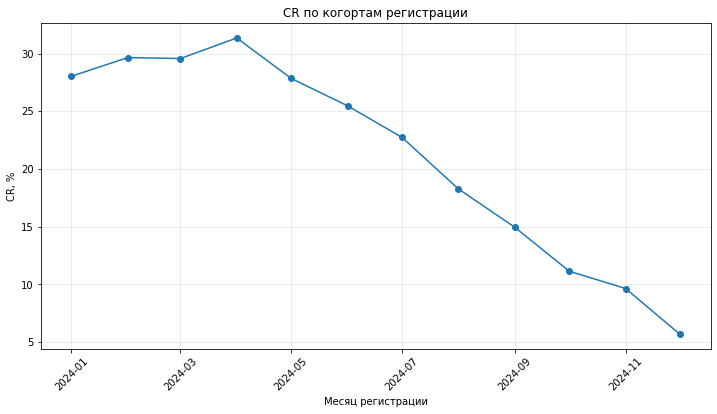

In [18]:
#Находим месяц первой покупки для каждого пользователя
first_order = pa_marketplace_orders.groupby('user_id')['order_month'].min().reset_index()
first_order.columns = ['user_id', 'first_order_month']

#Объединяем заказы с пользователями
users_with_orders = pd.merge(pa_marketplace_users, first_order, on='user_id', how='left')

#Считаем общее количество регистраций и покупок
cr_by_cohort = users_with_orders.groupby('cohort_month').agg(
    total_registered=('user_id', 'nunique'),
    made_purchase=('first_order_month', lambda x: x.notna().sum())  # сколько совершили покупку
).reset_index()
#Cчитаем CR из реги в покупку по когортам регистрации
cr_by_cohort['conversion_rate'] = (cr_by_cohort['made_purchase'] / cr_by_cohort['total_registered'] * 100).round(2)

# 4. Визуализируем
plt.figure(figsize=(12, 6))
plt.plot(cr_by_cohort['cohort_month'], cr_by_cohort['conversion_rate'], marker='o',)
plt.title('CR по когортам регистрации')
plt.xlabel('Месяц регистрации')
plt.ylabel('CR, %')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.show()


### 3.4. Метрики удержания


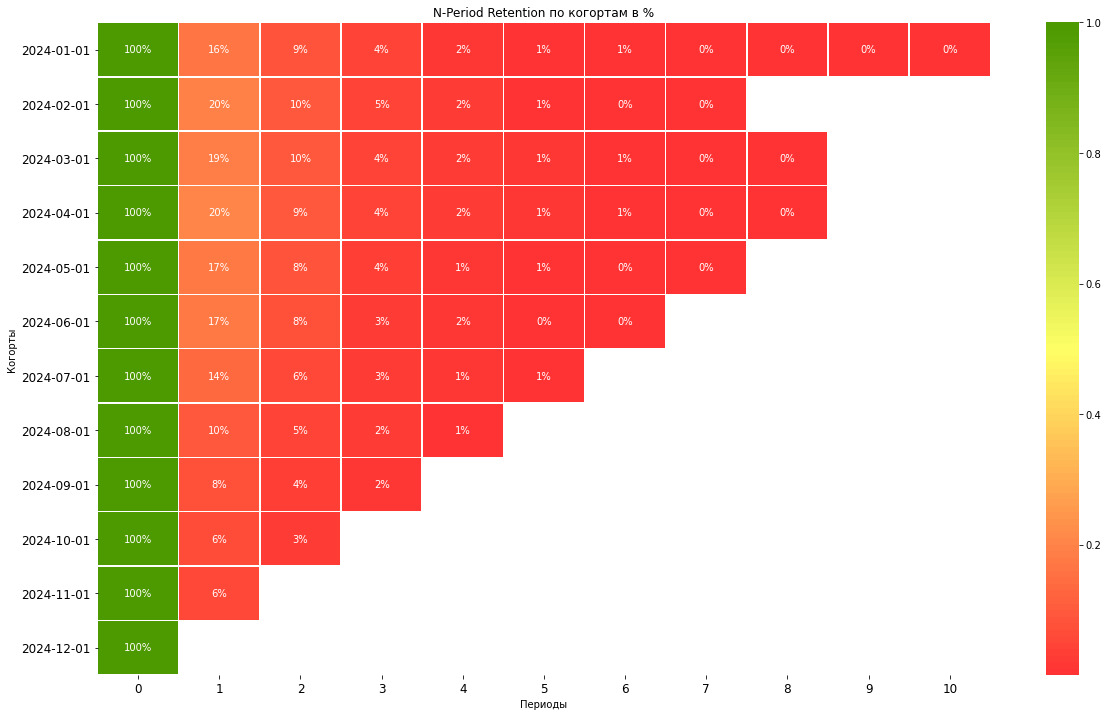

In [19]:
#Создаем таблицу с заказами и пользователями
retention_table =  pd.merge(pa_marketplace_users, pa_marketplace_orders, on='user_id', how='left')
#Заполняем нулями пустые значения в выручке
retention_table['revenue'] = retention_table['revenue'].fillna(0)
#Чтобы исключить некорректный расчет n_period заполним месяц заказа значением месяца когорты
retention_table['order_month'] = retention_table['order_month'].fillna(retention_table['cohort_month'])
#Cчитаем n_period и создаем сводную таблицу
retention_table['n_period'] = retention_table['order_month'].dt.to_period('M').astype('int64') - retention_table['cohort_month'].dt.to_period('M').astype('int64') 
retention_table['n_period'] = retention_table['n_period'].fillna(0)
data_pivot = pd.pivot_table(retention_table,
                           index='cohort_month',
                           columns='n_period',
                           values='user_id',
                            aggfunc='nunique',
                            fill_value=0
                           )

data_pivot = data_pivot.replace('', 0).astype('int')

#Каждое значение строки датафрейма делим на значение в периоде 0 с помощью функции div()
data_pivot = data_pivot.div(data_pivot[0], axis=0)

#Заменяем нули на пустые значения NaN. Это необходимо для корректной отрисовки визуализации в дальнейшем.
#Чтобы нули не были видны на графиках, заменим их на NaN.
data_pivot[data_pivot == 0] = float('nan')

cmap = mcolors.LinearSegmentedColormap.from_list('green_red', ['#FF3333', '#FFFF66', '#4C9900'], N=100) # красивые цвета heatmap

# Для корректного отображения индекса приведём его к типу ('%Y-%m-%d')
data_pivot.index = pd.to_datetime(data_pivot.index).strftime('%Y-%m-%d')

#Визуализируем
plt.subplots(figsize=(20,12))
sns.heatmap(data_pivot,
           cmap=cmap,
           annot=True,
           fmt='.0%',
           linewidth=0.5,
           annot_kws={"size": 10})

plt.title('N-Period Retention по когортам в %')
plt.xlabel('Периоды')
plt.ylabel('Когорты')
plt.yticks(rotation=0)
plt.tick_params(labelsize=12) # чтобы сделать подписи данных на оси Y (когорты пользователей) немного крупнее
plt.show()


1. **Аудитория и активность:**
   - **MAU и WAU** демонстрировали устойчивый рост до августа, после чего наступила стагнация. **DAU** показывал схожую динамику.
   - **Stickiness** стабильно снижался с апреля. Это ключевой тревожный сигнал: новая аудитория приходит, но не находит причин возвращаться регулярно. Продукт не становится "привычкой".

2. **Монетизация (верхний уровень):**
   - **Выручка (Revenue)** росла до августа, после чего начала снижаться, несмотря на продолжающийся рост аудитории в начале периода. Это указывает на проблемы с монетизацией трафика.
   - **ARPU** оставался относительно стабильным, без явного тренда на снижение.
   - **ARPPU** показывал тенденцию к снижению, что говорит об уменьшении среднего дохода с платящего пользователя.
   - **AOV (Средний чек)** также имеет тенденцию к небольшому росту.

3. **Конверсия в первую покупку (CR):**
   - **Критичное падение.** Конверсия из регистрации в первую покупку неуклонно снижалась весь год. Мы привлекаем все больше нецелевых пользователей, которые не готовы платить.

4. **Удержание (Retention):**
   - Удержание крайне низкое и ограничивается первыми месяцами. К 5-му месяцу в когорте практически не остается покупателей. Даже на второй месяц возвращается не более 20% пользователей. Продукт не формирует привычку к повторным покупкам.

**Общий вывод по этапу 2:** Продукт демонстрирует тревожные сигналы: рост аудитории не конвертируется в рост выручки, а качество привлекаемых пользователей (CR, Retention, Stickiness) ухудшается.


### 3. Оценка метрик монетизации и юнит-экономики


Выполните анализ монетизации. Определите, сколько зарабатывает продукт и сколько тратит на привлечение.

Важны как агрегированные метрики (ARPU, AOV), так и показатели эффективности (CAC, ROI, Payback Period).

Сформулируйте первые выводы по результатам анализа метрик. Сделайте это в формате записки для заказчика. Изложите все основные результаты так, чтобы прослеживалась связь между мыслями. Не пишите много — заказчик не будет читать записку полностью, а просто просмотрит.

Напишите выводы в конце блока, чтобы заказчик мог быстро ознакомиться с основными результатами.


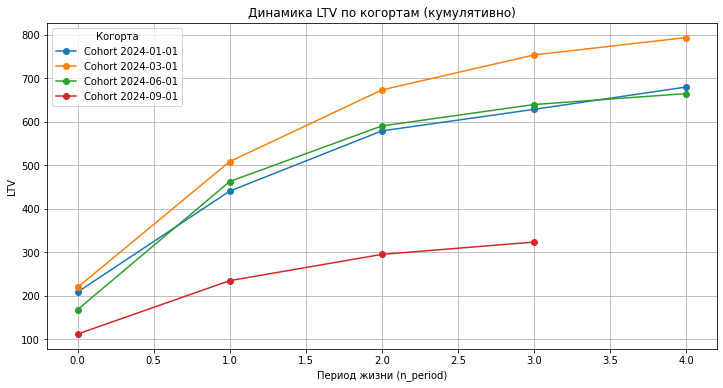

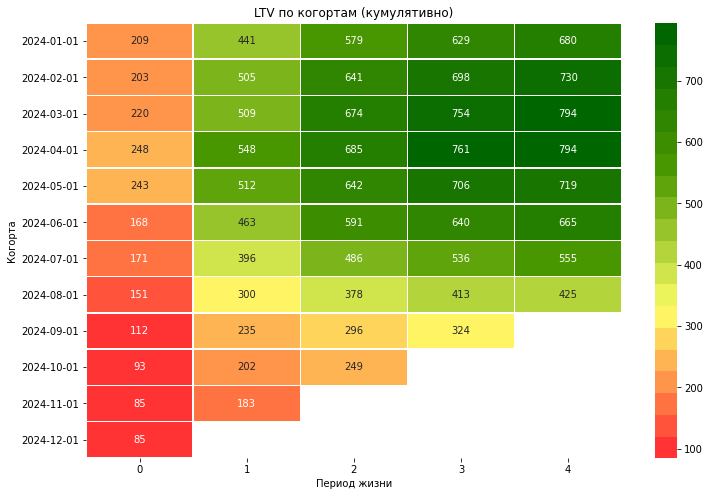

In [20]:
#Считаем кумулятивную выручку по когортам
cohort_revenue = retention_table.groupby(['cohort_month', 'n_period'])['revenue'].sum().reset_index()
cohort_revenue = cohort_revenue.sort_values(['cohort_month', 'n_period'])
cohort_revenue['cumulative_revenue'] = cohort_revenue.groupby('cohort_month')['revenue'].cumsum()
#Ограничим n_period 4 периодами, т.к дальше LTV выходит на плато
cohort_revenue = cohort_revenue[cohort_revenue['n_period'] <= 4]

#Считаем общее количество пользователей в каждой когорте
cohort_size = retention_table.groupby('cohort_month')['user_id'].nunique().reset_index()
cohort_size.columns = ['cohort_month', 'total_users']

#Объединяем и считаем LTV
ltv_data = pd.merge(cohort_revenue, cohort_size, on='cohort_month')
ltv_data['LTV'] = ltv_data['cumulative_revenue'] / ltv_data['total_users']

#Посмотрим только часть месяцев, чтобы не перегружать график
first_months = ['2024-01-01', '2024-03-01', '2024-06-01', '2024-09-01']

#Визуализируем
plt.figure(figsize=(12, 6))
for month in first_months:
    df_plot = ltv_data[ltv_data['cohort_month'] == month]
    plt.plot(df_plot['n_period'], df_plot['LTV'], marker='o', label=f'Cohort {month}')


plt.title('Динамика LTV по когортам (кумулятивно)')
plt.xlabel('Период жизни (n_period)')
plt.ylabel('LTV')
plt.grid(True)
plt.legend(title='Когорта')
plt.show()

#Создаем тепловую карту
df_pivot = ltv_data.pivot(index='cohort_month', columns='n_period', values='LTV')
df_pivot.index = pd.to_datetime(df_pivot.index).strftime('%Y-%m-%d')
cmap = mcolors.LinearSegmentedColormap.from_list('green_red', ['#FF3333', '#FFFF66', '#4C9900', '#006600'], N=20)
plt.figure(figsize=(12, 8))
sns.heatmap(df_pivot, cmap=cmap, annot=True, fmt='.0f', linewidths=0.5, annot_kws={"size": 10})
plt.title('LTV по когортам (кумулятивно)')
plt.xlabel('Период жизни')
plt.ylabel('Когорта')
plt.yticks(rotation=0)
plt.show()


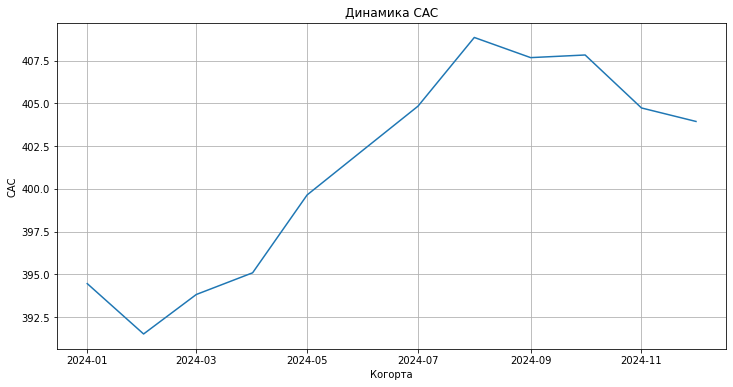

In [21]:
#Считаем CAC
#Группируем по когортам и считаем количество пользователей
client_counts = pa_marketplace_users.groupby('cohort_month')['user_id'].nunique().reset_index(name='user_counts')
#Считаем бюджет по месяцам
total_budget = pa_marketplace_campaign_costs.groupby('spend_month')['budget'].sum().reset_index()

#Объединяем бюджеты и количество клиентов и считаем CAC
cac_data = pd.merge(client_counts, total_budget, how='left', left_on = 'cohort_month', right_on = 'spend_month')
cac_data['cac'] = cac_data['budget'] / cac_data['user_counts']
plt.figure(figsize=(12,6))
plt.plot(cac_data['cohort_month'], cac_data['cac'])
plt.grid()
plt.title('Динамика CAC')
plt.xlabel('Когорта')
plt.ylabel('CAC')
plt.show()


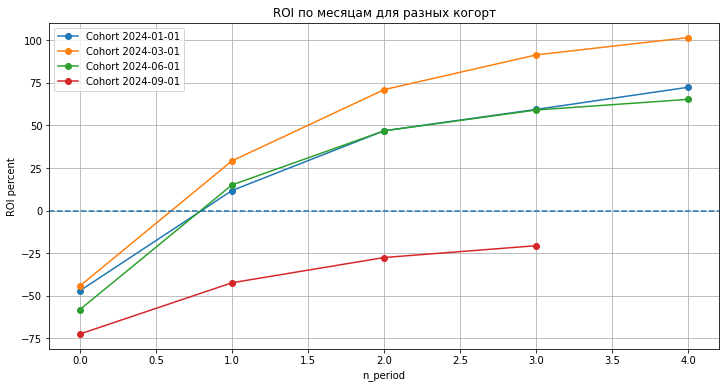

In [22]:
#Рассчитываем ROI на основе последнего доступного периода для каждой когорты
final_ltv = ltv_data.groupby(['cohort_month', 'n_period'])['LTV'].last().reset_index()
unit_data = pd.merge(final_ltv, cac_data, on='cohort_month')
unit_data['roi'] = ((unit_data['LTV'] - unit_data['cac']) / unit_data['cac']) * 100

#Создаем график
plt.figure(figsize=(12, 6))

#Строим по когортам
for month in first_months:
  df_plot = unit_data[unit_data['cohort_month'] == month]
  plt.plot(df_plot['n_period'], df_plot['roi'], marker='o', label=f'Cohort {month}')

# Добавим линию, выше которой когорта окупается
plt.axhline(y=0, linestyle='--')

plt.title('ROI по месяцам для разных когорт')
plt.xlabel('n_period')
plt.ylabel('ROI percent')
plt.legend()
plt.grid(True)
plt.show()


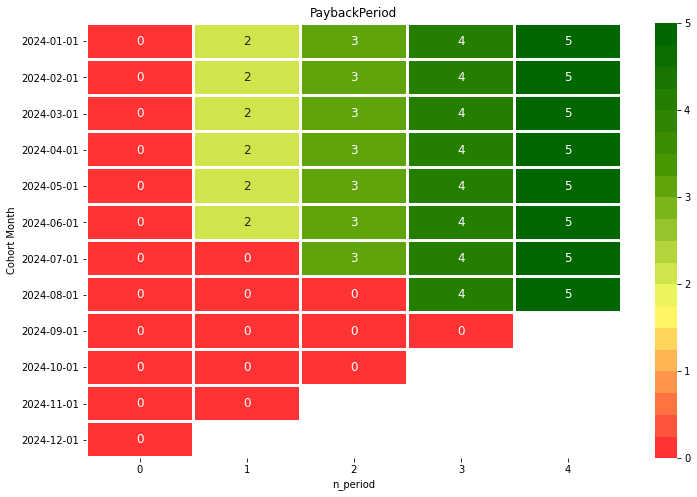

In [23]:
#Считаем Payback через lambda-функцию, в которой при условии LTV > CAC ставим 1, иначе 0
unit_data['Payback_Period'] = unit_data.apply(
  lambda row: row['n_period'] + 1 if row['LTV'] >= row['cac'] else 0, axis=1)

#Создаем пивот по когортам и значениями Payback
df_pivot = unit_data.pivot(index='cohort_month', columns='n_period', values='Payback_Period')
cmap = mcolors.LinearSegmentedColormap.from_list('green_red', ['#FF3333', '#FFFF66', '#4C9900', '#006600'], N=20)

#Строим heatmap
plt.figure(figsize=(12, 8))

df_pivot.index = pd.to_datetime(df_pivot.index).strftime('%Y-%m-%d')

sns.heatmap(df_pivot,
          cmap=cmap,
          annot=True,
          fmt='.0f',
          linewidths=2,
          annot_kws={"size": 12})


plt.title('PaybackPeriod')
plt.xlabel('n_period')
plt.ylabel('Cohort Month')
plt.show()


1. **Стоимость привлечения (CAC):**
   - Общий CAC рос с марта по август
  

2. **Ценность пользователя (LTV):**
   - LTV выходит на плато к 3-4 месяцу, после чего почти не растет. Это подтверждает вывод об отсутствии повторных покупок.
   - Наблюдается заметное снижение LTV у когорт, начиная с июня, что коррелирует с пиком расходов на привлечение.

3. **Окупаемость (ROI и Payback Period):**
   - В целом, ROI на второй месяц показывает положительную динамику, но его пик пришелся на весенние когорты (март-апрель).
   - Когорты, привлеченные во второй половине года, показывают значительно худшую экономику.
   - Период окупаемости (Payback Period) для большинства когорт составляет 2-3 месяца, но для поздних когорт он увеличивается, а некоторые еще не вышли на окупаемость.


## Выводы по этапам 2 и 3


Представьте ключевые выводы в текстовом виде здесь или приложите ссылку на документ с презентацией.

Не забудьте предоставить доступ на просмотр и комментирование документа.


Основной итог 2024 года — рост аудитории, не привел к пропорциональному росту выручки и сопровождался системным снижением ключевых показателей здоровья продукта. 
- Выручка росла только до августа, после чего начала снижаться, несмотря на продолжающийся рост аудитории. При этом конверсия в первую покупку (CR) критично упала с 28% до 19% за год — мы привлекаем все больше нецелевых пользователей, которые не готовы платить. 
- Удержание тоже вызывает вопросы: даже на второй месяц возвращается не более 20% покупателей, а к пятому месяцу retention стремится к нулю, из-за чего LTV выходит на плато уже к 3-4 месяцу и перестает расти. 
- Эффективность инвестиций падает: пик ROI пришелся на весенние когорты (март-апрель), а когорты с августа показывают значительно худшие результаты. Мы фактически субсидируем привлечение нелояльных пользователей за счет более качественных ранних когорт. Если не изменить подход, при сохранении текущих трендов CAC продолжит расти, CR — падать, а ROI станет отрицательным для большинства когорт.


## 4. Поиск инсайтов, точек роста и сегментация


После того как вы провели верхнеуровневую оценку данных, самое время переходить от общей картины к точечным наблюдениям. Посмотрите вглубь данных: по каналам,
сегментам пользователей, категориям товаров, регионам, типам устройств. Ищите
закономерности, различия, аномалии.

Цель — сформировать обоснованные гипотезы:

* какие сегменты работают лучше остальных
* какие сегменты работают хуже остальных
* на каких этапах воронки теряются пользователи
* какие группы можно или нужно масштабировать
* куда стоит инвестировать больше внимания или ресурсов

По итогам анализа также:

* сформулируйте в виде аналитической записки выводы
* сформулируйте несколько гипотез, которые помогут развить продукт. Например: «Если предлагать клиентам на iOS персонализированные скидки, то они станут чаще конвертировать в продукт». При формулировании гипотез опишите, на что вы опираетесь при её формировании. Например, на динамику метрики или на взаимосвязь метрик.

Напишите выводы в конце блока, чтобы заказчик мог быстро ознакомиться с основными результатами.


Google Ads


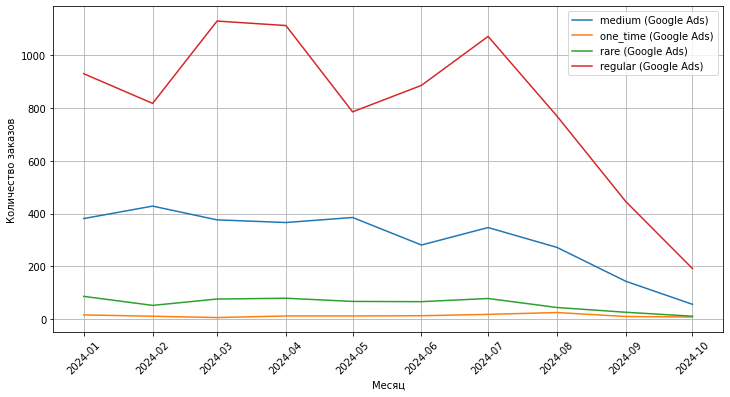

Email Marketing


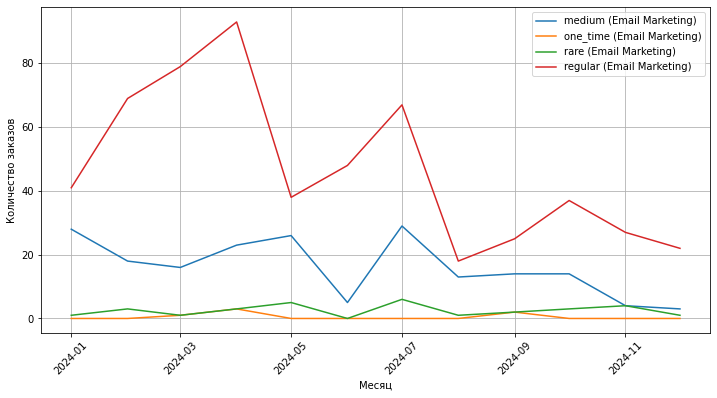

Affiliate


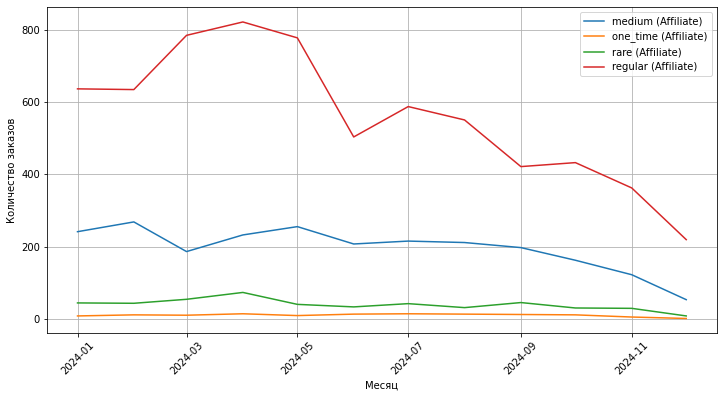

SEO


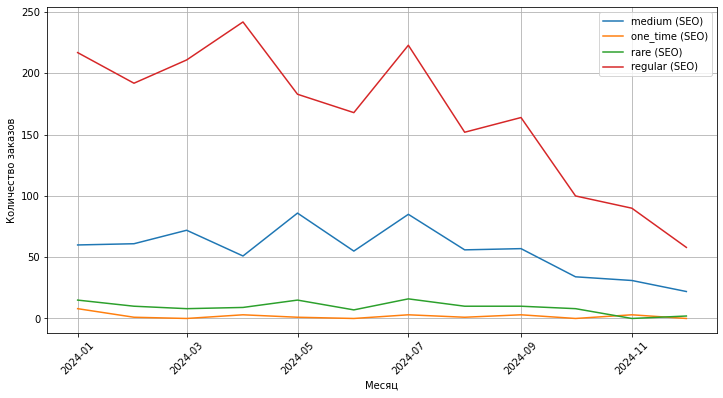

Social Media


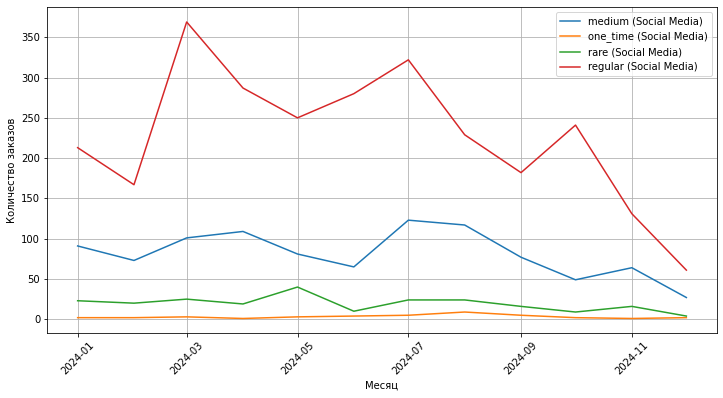

TikTok


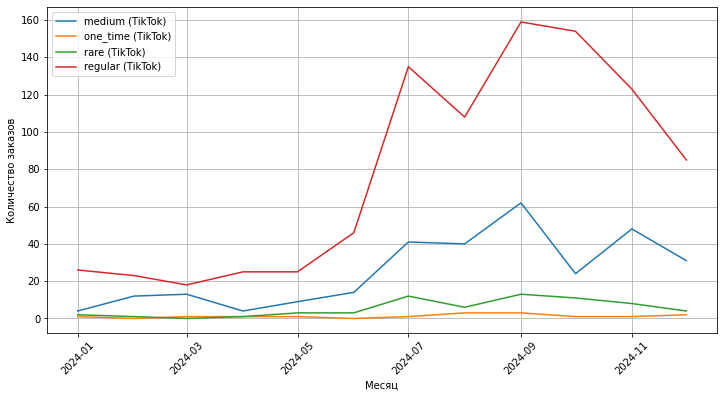

In [24]:
#Создаем функцию для построения графиков по сегментам
def plot_segments(data: pd.DataFrame, segmentation_attribute: str, channel_column: str) -> None:
   #Группировка данных по месяцам и категориям, суммирование выручки
   df_gp = data.groupby(["cohort_month", segmentation_attribute, channel_column], as_index=False)["order_id"].nunique().reset_index()
    

   #Получаем все уникальные сегменты
   segments = df_gp[segmentation_attribute].unique()
  

   #Строим график по каналу и сегменту
   for channel in data[channel_column].unique():
       plt.figure(figsize=(12, 6)) 
       for segment in segments:
           df_plot = df_gp[(df_gp[segmentation_attribute] == segment) & (df_gp[channel_column] == channel)]
           plt.plot(df_plot['cohort_month'], df_plot['order_id'], label=f"{segment} ({channel})")
       print(f'{channel}')

       plt.xlabel("Месяц")
       plt.ylabel("Количество заказов")

       plt.legend()
       plt.grid(True)
       plt.xticks(rotation=45)
       plt.show()

plot_segments(retention_table, "buyer_segment", "acq_channel")


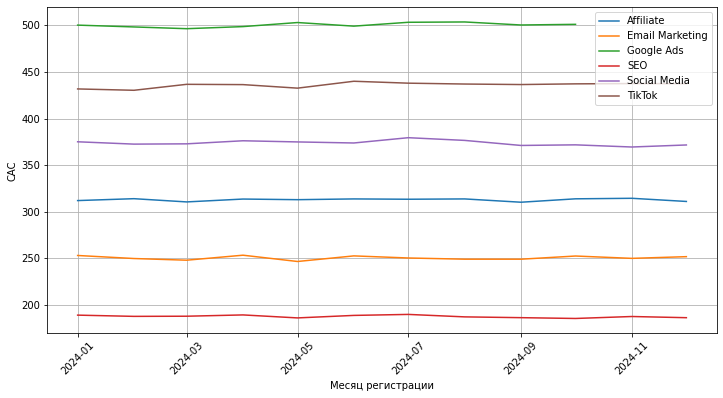

,acq_channel,cac
2,Google Ads,500.508673
5,TikTok,435.989843
4,Social Media,373.754273
0,Affiliate,312.717904
1,Email Marketing,250.390565
3,SEO,187.441035


In [25]:
#Считаем CAC по каналам
#Группируем юзеров по когортам и каналам
client_counts_channel = pa_marketplace_users.groupby(['cohort_month', 'acq_channel'])['user_id'].nunique().reset_index(name='user_counts_ch')
#Объединяем юзеров с костами по каналам
cac_data_channel = pd.merge(client_counts_channel, pa_marketplace_campaign_costs, how='left', left_on = ['acq_channel', 'cohort_month'], right_on = ['acq_channel', 'spend_month'])

cac_data_channel['cac'] = cac_data_channel['budget'] / cac_data_channel['user_counts_ch']

plt.figure(figsize=(12,6))

#Визуализируем график для каждого канала
for channel in cac_data_channel['acq_channel'].unique():
    df_plot = cac_data_channel[cac_data_channel['acq_channel'] == channel]
    plt.plot(df_plot['cohort_month'],df_plot['cac'], label=channel)
plt.legend()
plt.xlabel("Месяц регистрации")
plt.ylabel("CAC")
plt.grid(True)
plt.xticks(rotation=45)

plt.show()
cac_mean = cac_data_channel.groupby('acq_channel')['cac'].mean().reset_index()
cac_mean.sort_values(by='cac', ascending=False)


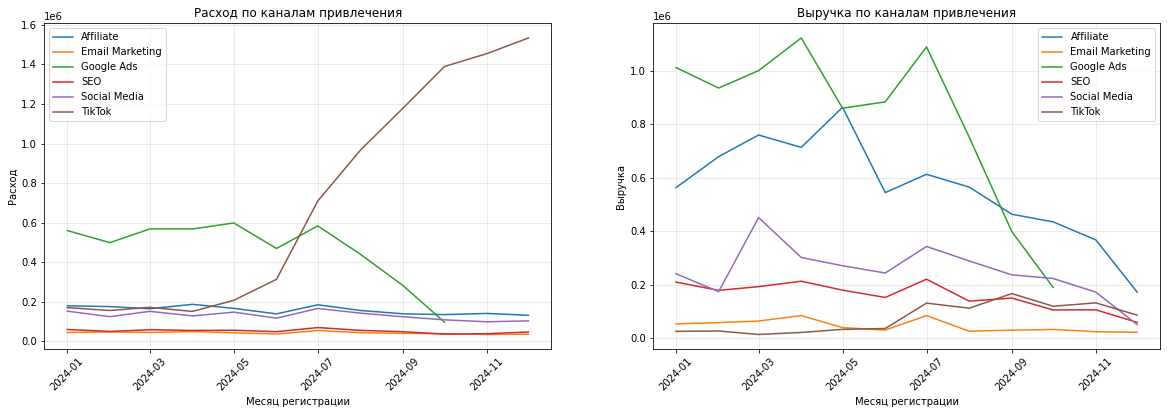

In [26]:
# 1. Revenue и CR по каналам привлечения

# Группируем по месяцу регистрации и каналу
channel_metrics = retention_table.groupby(['cohort_month', 'acq_channel']).agg(
    total_revenue=('revenue', 'sum'),
    total_users=('user_id', 'nunique'),
    paying_users=('user_id', lambda x: x[retention_table.loc[x.index, 'revenue'] > 0].nunique())
).reset_index()


#Создаем условия для визуализиации
segmentation_attribute = "acq_channel"
df_gp = channel_metrics.copy()
segments = df_gp[segmentation_attribute].unique()

#Визуализируем бюджет и выручку
plt.figure(figsize=(20, 6))

plt.subplot(1,2,1)
for segment in segments:
    df_plot = cac_data_channel[cac_data_channel[segmentation_attribute] == segment]
    plt.plot(df_plot['cohort_month'], df_plot['budget'], label=segment)
plt.title('Расход по каналам привлечения')
plt.xlabel('Месяц регистрации')
plt.ylabel('Расход')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1,2,2)
for segment in segments:
    df_plot = df_gp[df_gp[segmentation_attribute] == segment]
    plt.plot(df_plot['cohort_month'], df_plot['total_revenue'], label=segment)
plt.title('Выручка по каналам привлечения')
plt.xlabel('Месяц регистрации')
plt.ylabel('Выручка')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)


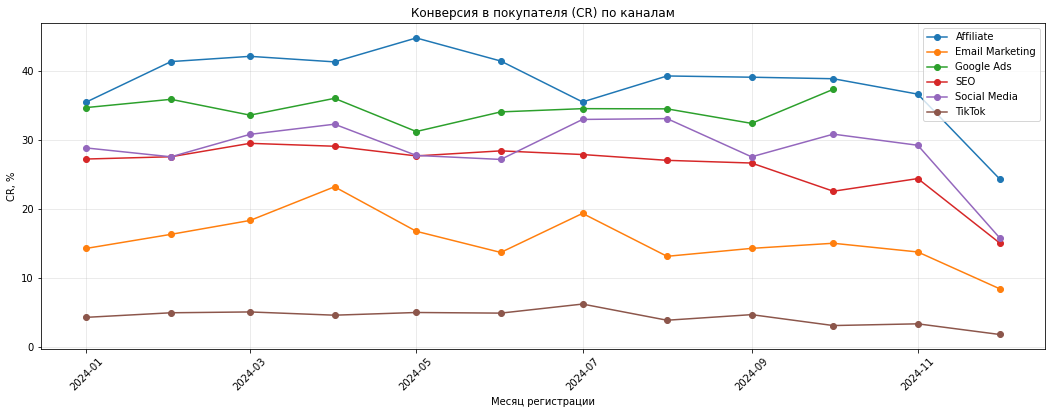

Сводка по каналам (среднее за год):


,avg_revenue,avg_cr,avg_arpu,avg_arppu,total_paid_users_all,total_users_all
acq_channel,,,,,,
Affiliate,561317.90,38.32,1093.67,2799.31,2338,6069
Google Ads,823676.02,34.40,885.02,2566.65,3187,9319
Social Media,250021.23,28.64,703.17,2400.48,1211,4179
SEO,159161.23,26.08,570.21,2164.51,874,3312
Email Marketing,46308.23,15.55,262.09,1662.98,325,2044
TikTok,75870.68,4.34,55.01,1273.16,719,19228


,cohort_month,acq_channel,total_revenue,total_users,paying_users,CR,ARPU,ARPPU
0,2024-01-01,Affiliate,562577.7950,575,204,35.48,978.40,2757.73
6,2024-02-01,Affiliate,678519.2015,559,231,41.32,1213.81,2937.31
12,2024-03-01,Affiliate,759197.0910,530,223,42.08,1432.45,3404.47
18,2024-04-01,Affiliate,713029.0025,596,246,41.28,1196.36,2898.49
24,2024-05-01,Affiliate,862685.4970,532,238,44.74,1621.59,3624.73
30,2024-06-01,Affiliate,544226.4805,442,183,41.40,1231.28,2973.92
36,2024-07-01,Affiliate,612497.4340,589,209,35.48,1039.89,2930.61
42,2024-08-01,Affiliate,564720.4970,497,195,39.24,1136.26,2896.00
48,2024-09-01,Affiliate,463416.7780,448,175,39.06,1034.41,2648.10
54,2024-10-01,Affiliate,434853.9025,430,167,38.84,1011.29,2603.92


In [27]:
# Считаем CR и ARPU,ARPPU
channel_metrics['CR'] = (channel_metrics['paying_users'] / channel_metrics['total_users'] * 100).round(2)
channel_metrics['ARPU'] = (channel_metrics['total_revenue'] / channel_metrics['total_users']).round(2)
channel_metrics['ARPPU'] = (channel_metrics['total_revenue'] / channel_metrics['paying_users']).round(2)

# Строим визуализацию CR по каналам
plt.figure(figsize=(18, 6))
for segment in segments:
    df_plot = channel_metrics[channel_metrics[segmentation_attribute] == segment]
    plt.plot(df_plot['cohort_month'], df_plot['CR'], marker='o', label=segment)
plt.title('Конверсия в покупателя (CR) по каналам')
plt.xlabel('Месяц регистрации')
plt.ylabel('CR, %')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Выводим таблицу с основнымии показателями
print("Сводка по каналам (среднее за год):")
channel_summary = channel_metrics.groupby('acq_channel').agg(
    avg_revenue=('total_revenue', 'mean'),
    avg_cr=('CR', 'mean'),
    avg_arpu=('ARPU', 'mean'),
    avg_arppu=('ARPPU', 'mean'),
    total_paid_users_all=('paying_users', 'sum'),
    total_users_all=('total_users', 'sum')
).round(2)
display(channel_summary.sort_values('avg_cr', ascending=False))

channel_metrics[channel_metrics['acq_channel']=='Affiliate']


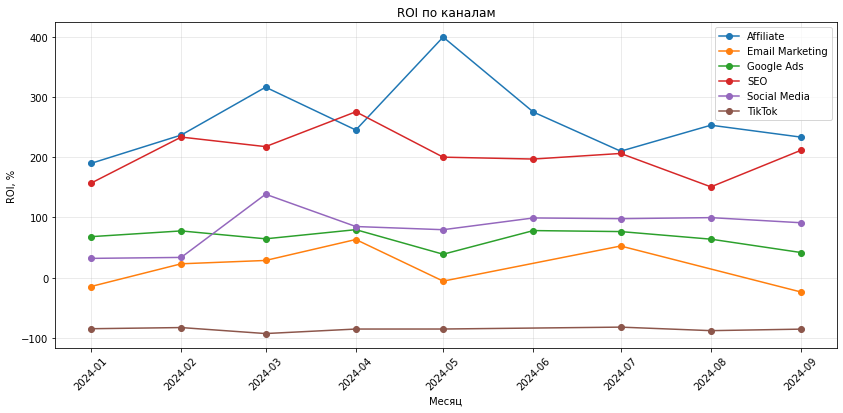

ROI по каналам (среднее за год):


,avg_roi,avg_ltv,avg_cac
acq_channel,,,
Affiliate,262.38,1132.81,312.61
SEO,205.62,574.13,187.83
Social Media,84.02,689.55,374.69
Google Ads,65.36,827.41,500.43
Email Marketing,17.42,293.67,249.91
TikTok,-86.20,59.99,434.94


In [28]:
#Cчитаем накопленную выручку по каналам
channel_ltv = retention_table.groupby(['cohort_month', 'acq_channel', 'n_period'])['revenue'].sum().reset_index()
channel_ltv = channel_ltv.sort_values(['cohort_month', 'acq_channel', 'n_period'])
channel_ltv['cumulative_revenue'] = channel_ltv.groupby(['cohort_month', 'acq_channel'])['revenue'].cumsum()


# Объединяем и считаем LTV на пользователя
channel_ltv = pd.merge(channel_ltv, channel_metrics, on=['cohort_month', 'acq_channel'], how='inner')
channel_ltv['LTV'] = channel_ltv['cumulative_revenue'] / channel_ltv['total_users']

# Берем последний период (n_period = 3) для каждой когорты
final_ltv = channel_ltv[channel_ltv['n_period'] == 3].copy()

# Объединяем с CAC по каналам
roi_channel = pd.merge(final_ltv[['cohort_month', 'acq_channel', 'LTV']], 
                       cac_data_channel[['cohort_month', 'acq_channel', 'cac']], 
                       on=['cohort_month', 'acq_channel'], 
                       how='inner')

#Считаем ROI
roi_channel['ROI'] = ((roi_channel['LTV'] - roi_channel['cac']) / roi_channel['cac'] * 100).round(2)

# Визуализируем
plt.figure(figsize=(14, 6))
for channel in segments:
    df_plot = roi_channel[roi_channel['acq_channel'] == channel]
    plt.plot(df_plot['cohort_month'], df_plot['ROI'], marker='o', label=channel)
plt.title('ROI по каналам')
plt.xlabel('Месяц')
plt.ylabel('ROI, %')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#Таблица по каналам со средними
roi_summary = roi_channel.groupby('acq_channel').agg(
    avg_roi=('ROI', 'mean'),
    avg_ltv=('LTV', 'mean'),
    avg_cac=('cac', 'mean')
).round(2)

print("ROI по каналам (среднее за год):")
display(roi_summary.sort_values('avg_roi', ascending=False))


,category_name,total_orders,total_revenue,total_revenues,paid_users,sum_quantity,AOV,avg_quant,revenue_share
11,Мебель для дома,979,3.580998e+06,71619964.45,514,1964,73156.25,2.01,16.28
2,Бытовая техника,1030,2.248933e+06,44978661.11,546,2059,43668.60,2.00,10.22
24,Украшения и часы,1024,1.718297e+06,34365942.06,495,2058,33560.49,2.01,7.81
18,Спортивный инвентарь,1000,1.165361e+06,23307222.90,523,2021,23307.22,2.02,5.30
23,Товары для туризма,970,1.137318e+06,22746355.71,498,1949,23449.85,2.01,5.17
0,Автотовары,1043,1.044822e+06,20896434.84,561,2123,20034.93,2.04,4.75
21,Товары для кухни,1237,1.030402e+06,20608036.11,637,2462,16659.69,1.99,4.68
15,Обувь мужская,1253,9.424817e+05,18849633.69,730,2482,15043.60,1.98,4.28
20,Сумки и аксессуары,1180,8.734911e+05,17469822.79,711,2311,14804.93,1.96,3.97
14,Обувь женская,1211,8.604892e+05,17209783.72,757,2424,14211.22,2.00,3.91


<Figure size 864x576 with 0 Axes>

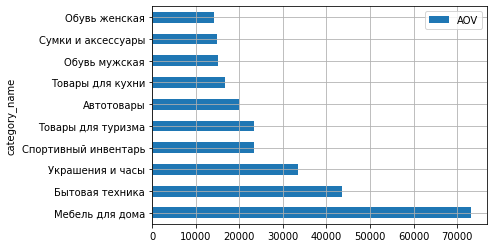

In [29]:
#Считаем эффективность по товарным категориям
#По каждой грппуе считаем количество заказов, выручку, количество покупателей и среднее количество товаров в заказа
cat_orders_group = pa_marketplace_orders.groupby('category_name').agg (
     total_orders = ('order_id','nunique'),
      total_revenue = ('revenue','sum'),
        total_revenues = ('total_price','sum'),
      paid_users = ('user_id','nunique'),
     sum_quantity =('quantity','sum')
    ).reset_index()
cat_orders_group.sort_values(by='total_revenue', ascending=False)

#Считаем средний чек и среднее количество товаров в заказе
cat_orders_group['AOV'] = (cat_orders_group['total_revenues'] / cat_orders_group['total_orders']).round(2)
cat_orders_group['avg_quant'] = (cat_orders_group['sum_quantity'] / cat_orders_group['total_orders']).round(2)
cat_orders_group.sort_values(by='total_revenue', ascending=False)

#Рассчитываем долю в общей выручке
cat_orders_group['revenue_share'] = (cat_orders_group['total_revenue'] / cat_orders_group['total_revenue'].sum() * 100).round(2)

#Оставим только топ 10 категорий по выручке
top_10_categories = cat_orders_group.sort_values(by='total_revenue', ascending=False).head(10)
display(top_10_categories)

plt.figure(figsize=(12,8))

top_10_categories.plot(kind='barh', x='category_name', y='AOV')
plt.grid(True)
plt.show()


In [30]:
#Создаем таблицу с заказами и пользователями
orders_with_channel = pd.merge(pa_marketplace_orders, 
                                pa_marketplace_users[['user_id', 'acq_channel']], 
                                on='user_id', how='left')

#Группируем по каналу и категории и рассчитываем метрики
channel_category = orders_with_channel.groupby(['acq_channel', 'category_name']).agg(total_orders = ('order_id','nunique'),
      total_revenue = ('revenue','sum'),
        total_revenues = ('total_price','sum'),                                                                             
      paid_users = ('user_id','nunique'),
      sum_quantity =('quantity','sum')).reset_index()

#Считаем средний чек
channel_category['AOV'] = channel_category['total_revenues'] / channel_category['total_orders']

#Определяем топ3 категории по каждому каналу и выводим ключевые метрики
for channel in channel_category['acq_channel'].unique():
    df_channel = channel_category[channel_category['acq_channel'] == channel]
    top_3 = df_channel.sort_values(by='total_revenue', ascending=False).head(3)
    print(f"\n==={channel} ===")
    print(top_3[['category_name', 'AOV', 'total_revenue', 'total_orders']])



===Affiliate ===
       category_name           AOV  total_revenue  total_orders
11   Мебель для дома  72571.686092   1.030518e+06           284
2    Бытовая техника  44834.253471   7.038978e+05           314
24  Украшения и часы  33407.147468   5.211515e+05           312

===Email Marketing ===
       category_name           AOV  total_revenue  total_orders
27   Бытовая техника  41753.197273     68892.7755            33
49  Украшения и часы  39782.442353     67630.1520            34
36   Мебель для дома  58026.541000     58026.5410            20

===Google Ads ===
       category_name           AOV  total_revenue  total_orders
61   Мебель для дома  72376.397131   1.273825e+06           352
52   Бытовая техника  44127.335856   7.987048e+05           362
74  Украшения и часы  32474.913808   6.949632e+05           428

===SEO ===
           category_name           AOV  total_revenue  total_orders
86       Мебель для дома  76309.831385    248006.9520            65
77       Бытовая техник

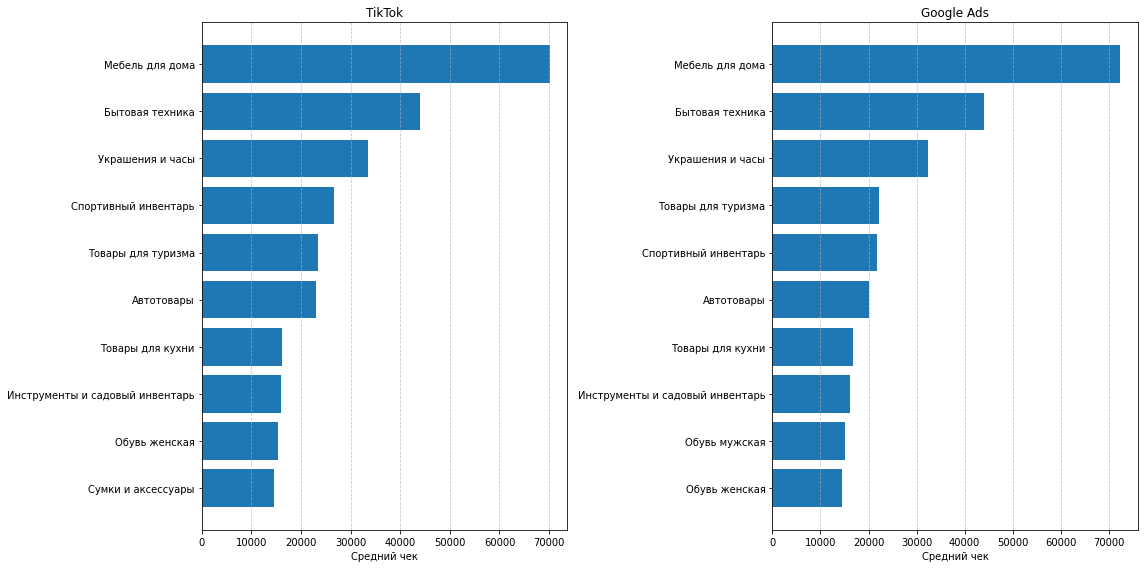

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
#Посмотрим средний чек топ10 категорий по ключевым каналам привлечения
for i, channel in enumerate(['TikTok', 'Google Ads']):
    df_plot = channel_category[channel_category['acq_channel'] == channel]
    df_plot = df_plot.sort_values(by='AOV', ascending=True).tail(10)
    axes[i].barh(df_plot['category_name'], df_plot['AOV'])
    axes[i].set_title(channel)
    axes[i].set_xlabel('Средний чек')
    axes[i].grid(axis='x', linestyle='--', alpha=0.7) 
  

plt.tight_layout()
plt.show()


In [32]:

#Задаем этапы воронки
event_list = ["page_view", "add_to_cart", "checkout_start", "checkout_complete"]

results = []

#Для каждого этапа считаем количество пользователей и добавляем в список
for event in event_list:
    count = pa_marketplace_events[pa_marketplace_events['event_type'] == event]['user_id'].nunique()
    results.append((event, count))

#Считаем пользователей с заказами
paid_users = pa_marketplace_orders['user_id'].nunique()

# Добавляем покупки
results.append(("paid", paid_users))

# Формируем таблицу
funnels = pd.DataFrame(results, columns=['Этап', 'Пользователи'])

# Конверсии
funnels['Конверсия от пред. этапа (%)'] = (funnels['Пользователи'] / funnels['Пользователи'].shift(1)) * 100
funnels['Конверсия от просмотра страницы (%)'] = (funnels['Пользователи'] / funnels['Пользователи'].iloc[0]) * 100

funnels


,Этап,Пользователи,Конверсия от пред. этапа (%),Конверсия от просмотра страницы (%)
0,page_view,22098,NaN,100.000000
1,add_to_cart,20411,92.365825,92.365825
2,checkout_start,16769,82.156680,75.884695
3,checkout_complete,13897,82.873159,62.888044
4,paid,8922,64.200907,40.374695


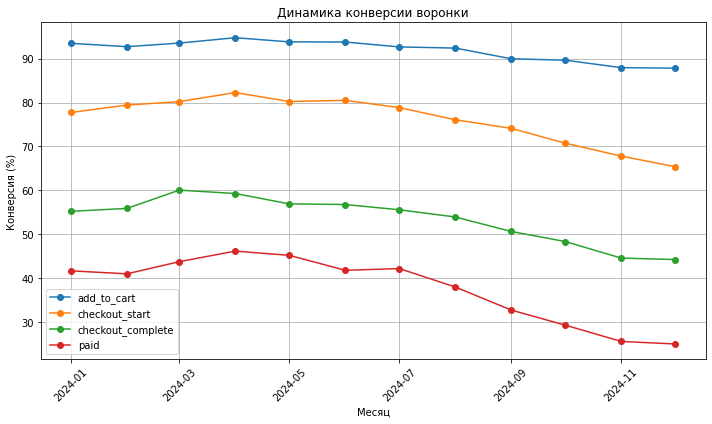

In [33]:
plt.figure(figsize=(10, 6))

#Считаем знаменатель, первый этап воронки page_view
base = pa_marketplace_events[pa_marketplace_events['event_type'] == 'page_view']
base = base.groupby('event_month')['user_id'].nunique().reset_index(name='page_view_base')

#Считаем и визуализируем конверсию для каждого события
for event in event_list[1:]:
    df_event = pa_marketplace_events[pa_marketplace_events['event_type'] == event]
    df_event = df_event.groupby('event_month')['user_id'].nunique().reset_index(name=event)
    df_event = df_event.merge(base, on='event_month', how='left')
    df_event['conversion'] = (df_event[event] / df_event['page_view_base']) * 100
    plt.plot(df_event['event_month'], df_event['conversion'], marker='o', label=event)

#Добавляем заказы как финальный этам
df_paid = pa_marketplace_orders.groupby('order_month')['user_id'].nunique().reset_index(name='paid')
df_paid = df_paid.merge(base, left_on='order_month', right_on='event_month', how='left')
df_paid['conversion'] = (df_paid['paid'] / df_paid['page_view_base']) * 100
plt.plot(df_paid['order_month'], df_paid['conversion'], marker='o', label='paid')

#Создаем график
plt.title('Динамика конверсии воронки')
plt.xlabel('Месяц')
plt.ylabel('Конверсия (%)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [34]:
#Создаем функцию для расчета воронки по каналу
def funnel_by_channel(channel_name):
    #Создаем таблицу с событиями и пользователями
    events_channel = pa_marketplace_events.merge(
        pa_marketplace_users[['user_id', 'acq_channel', 'cohort_month']], 
        on='user_id', how='left'
    )
    events_channel = events_channel[events_channel['acq_channel'] == channel_name]
    
    #Считаем воронку для каждого события воронки
    results = []
    for event in event_list:
        count = events_channel[events_channel['event_type'] == event]['user_id'].nunique()
        results.append((event, count))
    
    #Добавляем заказы к пользователями
    orders_channel = pa_marketplace_orders.merge(
        pa_marketplace_users[['user_id', 'acq_channel']], 
        on='user_id', how='left'
    )
    orders_channel = orders_channel[orders_channel['acq_channel'] == channel_name]
    paid_count = orders_channel['user_id'].nunique()
    results.append(("paid", paid_count))
    
    # Формируем таблицу
    funnel_df = pd.DataFrame(results, columns=['Этап', 'Пользователи'])
    funnel_df['Конверсия от пред. этапа (%)'] = (funnel_df['Пользователи'] / funnel_df['Пользователи'].shift(1)) * 100
    funnel_df['Конверсия от page_view (%)'] = (funnel_df['Пользователи'] / funnel_df['Пользователи'].iloc[0]) * 100
    
    return funnel_df

# Сравниваем каналы
for channel in ['TikTok', 'Google Ads']:
    print(f"\n=== {channel} ===")
    display(funnel_by_channel(channel))



=== TikTok ===


,Этап,Пользователи,Конверсия от пред. этапа (%),Конверсия от page_view (%)
0,page_view,6651,NaN,100.000000
1,add_to_cart,5649,84.934596,84.934596
2,checkout_start,3849,68.135953,57.870997
3,checkout_complete,2633,68.407379,39.588032
4,paid,719,27.307254,10.810404



=== Google Ads ===


,Этап,Пользователи,Конверсия от пред. этапа (%),Конверсия от page_view (%)
0,page_view,5611,NaN,100.000000
1,add_to_cart,5344,95.241490,95.241490
2,checkout_start,4676,87.500000,83.336304
3,checkout_complete,4105,87.788708,73.159865
4,paid,3187,77.637028,56.799145


## Выводы по этапу 4


Представьте ключевые выводы в текстовом виде здесь или приложите ссылку на документ с презентацией.

Не забудьте предоставить доступ на просмотр и комментирование документа.


# Аналитическая записка по итогам анализа эффективности каналов привлечения

**Период анализа:** 2026 год

---

### Ключевой вывод

Масштабирование убыточного TikTok при одновременном отказе от Google Ads и недофинансировании эффективных каналов привело к падению общей конверсии и потере качественной аудитории. Проблема носит структурный характер и требует пересмотра стратегии распределения бюджета.

---

#### Основные проблемы

**1. Масштабировали убыточный TikTok**

ROI каналы был отрицательный в течение всего года. С июля 2026 года бюджет TikTok вырос в 7,5 раз, при этом выручка почти не изменилась. Канал показал наихудшие результаты среди всех: самую низкую конверсию в покупку, минимальную выручку на покупателя. Рост доли TikTok в трафике обрушил общую конверсию продукта — она упала с 30% до 6%.

**2. Остановили эффективный Google Ads**

Google Ads приносил максимальную выручку и имел лучший LTV. С августа бюджет начали сокращать, а с октября полностью прекратили инвестиции. Это немедленно отразилось на общей выручке компании.

**3. Недооценённые Affiliate и SEO**

Affiliate и SEO показали наилучшую окупаемость (ROI выше 200%) и минимальную стоимость привлечения. Однако их бюджеты не росли, несмотря на доказанную эффективность. Потенциал этих каналов остался неиспользованным.

**4. Потеря лояльной аудитории**

Сегмент регулярных покупателей, который исторически приносил основную долю заказов, сократился во всех каналах, кроме TikTok. Но аудитория из TikTok хуже конвертируется и приносит меньше выручки, что при росте доли снизило все метрики

---

#### Анализ воронки

##### Главный барьер — переход к оплате

73% пользователей TikTok, начавших оформление заказа, не доходят до оплаты. В Google Ads этот показатель — всего 23%. При этом топ-категории товаров и средние чеки в TikTok и Google Ads практически одинаковы.

**Вывод:** Проблема не в ассортименте, а в процессе оформления заказа. Пользователи TikTok бросают покупку на последнем шаге.

---

### Итоговые выводы

1. **TikTok не оправдал инвестиций.** Масштабирование канала привело к сжиганию бюджета без значимого прироста выручки и обрушило общую конверсию продукта.

2. **Отказ от Google Ads был преждевременным.** Потеря самого доходного канала не была компенсирована другими источниками трафика.

3. **Эффективные каналы недополучают ресурсы.** Affiliate и SEO демонстрируют высокую окупаемость, но их бюджеты не растут.

4. **Продукт теряет постоянных покупателей.** Снижение доли регулярных заказов в ключевых каналах — тревожный сигнал, требующий отдельного внимания.

5. **Ключевая точка роста — этап оплаты.** Упрощение оформления заказа для пользователей TikTok может значительно повысить конверсию без дополнительных затрат на трафик.


### Гипотезы
1. Перераспределение бюджета с убыточного канала TikTok в Affilate и SEO позволит нарастить выручку, 
снизить средний CAC и выровнять экономику проекта. Сейчас ТикТок убыточен и имеют максимальную долю в структуре пользователей и бюджета, что влияет на средние метрики по проекту.
2. Рекомендуем запустить ретаргетинговые сценарии на аудиторию регулярных покупателей с помощью Google Ads или CRM-маркетинга. Это поможет нарастить retention пользователей в покупку и вернуть аудиторию, которые покупали регулярно. Сейчас эта аудитория снизилась по всем каналам, кроме ТикТока.
3. Если канал ТикТок важен рекомендую проанализировать причины отказов от оплаты и при необходимости протестировать упрощение сценариев оплаты, чтобы снизить потери на этапе перехода к оплате. Рекомендация связана с тем, что на этапе перехода к оплате мы теряем 77% пользователей привлеченных через Тик-Ток.
4. Рекомендуем наращивать инвестиции в продвижение категорий "Мебель" и "Бытовая техника", т.к они имеют наибольший средний чек и слабо привязаны к сезонности, в отличие от украшений, спортивных и туристических товаров.


## 5. Подготовка эксперимента и подведение его результатов


# Новые вводные (после этапа 4)
Команда продукта рассмотрела твои гипотезы и на основании этого решила влиять на конверсию при помощи финансовых стимуляций. Так как ситуация со снижением выручки срочная и безотлагательная, пока ты продолжал изучать данные, они подключили другого аналитика для подготовки дизайн документа, но само проведение эксперимента на тебе.


При формировании выводов допиши рекомендации по итогам теста и, если необходимо, опиши проблемы, присутствующие в эксперименте.


## Новые данные:
```python
pa_marketplace_events_AB = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_events_AB.csv')
pa_marketplace_orders_AB = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_orders_AB.csv')
pa_marketplace_users_AB = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_users_AB.csv')
```
## Результаты сплита лежат в таблице:
```python
pa_marketplace_AB_split_users = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_AB_split_users.csv')
```
* user_id – id клиента
* group – группа, в которую попал клиент


# Дизайн эксперимента: Бонус на первую покупку для пользователей TikTok
## 1. Контекст и цель эксперимента
- **Бизнес-контекст:** Команда продукта запускает эксперимент, направленный на повышение конверсии среди пользователей, привлечённых через канал TikTok. Для стимулирования первой покупки пользователям будет предоставлен бонус на первую покупку.
- **Цель:** Проверить, влияет ли предоставление бонуса на первую покупку на конверсию и выручку среди пользователей TikTok.
- **Гипотеза:** Предоставление бонуса на первую покупку новым пользователям, привлеченным через TikTok, приведет к увеличению конверсии в первую покупку
---
## 2. Формат эксперимента
- **Тип эксперимента:** Сплит-роллинг (rolling split)
- **Канал:** Только пользователи, пришедшие с TikTok
- **Группы:**
    - **Контрольная (A):** пользователи TikTok без бонуса
    - **Тестовая (B):** пользователи TikTok с бонусом на первую покупку
- **Распределение:** Равномерное распределение новых пользователей TikTok между группами по дате регистрации
- **Период проведения:** 3 недели (фиксировано)
---
## 3. Ключевые метрики
### Основная метрика
- **Конверсия в первую покупку** — доля пользователей, зарегистрировавшихся с TikTok и совершивших первую покупку
- *Цель:* увеличить конверсию с помощью бонуса
- *Критерий успеха:* статистически значимый рост конверсии в тестовой группе
### Вспомогательные метрики
- **ARPU** (средняя выручка на пользователя TikTok)
- **ARPPU** (средняя выручка на покупателя TikTok)
- **AOV** (средний чек TikTok)
### Барьерная метрика
- **Общая выручка от пользователей TikTok**
---
## 4. Размеры групп и запуск
- **Целевая аудитория:** только пользователи TikTok
- **Размеры групп:** определяются по фактическому трафику TikTok за период эксперимента
- **Комментарий:** запуск без предварительного расчёта мощности и MDE из-за срочности задачи


In [ ]:
from scipy.stats import ttest_ind
import matplotlib.dates as mdates


In [ ]:
pa_marketplace_events_AB = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_events_AB.csv', parse_dates = ['event_date', 'event_month', 'event_week'])
pa_marketplace_orders_AB = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_orders_AB.csv', parse_dates = ['order_date', 'order_month', 'order_week'])
pa_marketplace_users_AB = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_users_AB.csv', parse_dates = ['registration_date', 'cohort_month', 'cohort_week'])
pa_marketplace_AB_split_users = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_AB_split_users.csv')


In [37]:
#Познакомимся с датасетами
display(pa_marketplace_users_AB.head())
display(pa_marketplace_events_AB.head())
display(pa_marketplace_orders_AB.head())
display(pa_marketplace_AB_split_users.head())


,user_id,registration_date,age,gender,region,acq_channel,buyer_segment,cohort_week,cohort_month
0,18,2024-01-01 05:26:00,49,M,Екатеринбург,TikTok,one_time,2024-01-01,2024-01-01
1,22,2024-01-01 17:13:00,50,M,Санкт-Петербург,TikTok,one_time,2024-01-01,2024-01-01
2,26,2024-01-01 21:15:00,60,F,Москва,TikTok,rare,2024-01-01,2024-01-01
3,33,2024-01-01 14:43:00,31,M,Екатеринбург,TikTok,rare,2024-01-01,2024-01-01
4,39,2024-01-01 01:13:00,44,M,Санкт-Петербург,TikTok,rare,2024-01-01,2024-01-01


,event_id,user_id,event_date,event_type,os,device,product_name,event_week,event_month
0,3132,100,2024-01-01 15:23:56,page_view,iOS,mobile,NaN,2024-01-01,2024-01-01
1,3133,100,2024-01-01 15:24:01,product_view,iOS,mobile,Шорты для тренировок,2024-01-01,2024-01-01
2,3134,100,2024-01-01 15:24:10,product_click,iOS,mobile,Куртка детская,2024-01-01,2024-01-01
3,3135,100,2024-01-01 15:25:10,add_to_cart,iOS,mobile,Балетки классические,2024-01-01,2024-01-01
4,3136,100,2024-01-01 15:25:46,checkout_start,iOS,mobile,NaN,2024-01-01,2024-01-01


,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month
0,1,3,2024-01-19 01:52:52,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
1,2,3,2024-01-19 01:52:52,Молоток слесарный,1,11340.38,11340.38,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
2,3,3,2024-01-19 01:52:52,Секатор садовый,2,10892.09,21784.18,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
3,4,3,2024-01-25 13:59:38,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-22,2024-01-01
4,5,3,2024-01-25 13:59:38,Чай черный,1,2099.59,2099.59,Продукты питания,2024-01-22,2024-01-01


,user_id,group
0,44965,control
1,44967,control
2,44968,control
3,44969,treatment
4,44970,control


In [38]:
#Выведем ключевую информацию от датасетах
display(pa_marketplace_users_AB.info())
display(pa_marketplace_events_AB.info())
display(pa_marketplace_orders_AB.info())
display(pa_marketplace_AB_split_users.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22196 entries, 0 to 22195
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            22196 non-null  int64         
 1   registration_date  22196 non-null  datetime64[ns]
 2   age                22196 non-null  int64         
 3   gender             22196 non-null  object        
 4   region             22196 non-null  object        
 5   acq_channel        22196 non-null  object        
 6   buyer_segment      22196 non-null  object        
 7   cohort_week        22196 non-null  datetime64[ns]
 8   cohort_month       22196 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int64(2), object(4)
memory usage: 1.5+ MB


None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 831231 entries, 0 to 831230
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   event_id      831231 non-null  int64         
 1   user_id       831231 non-null  int64         
 2   event_date    831231 non-null  datetime64[ns]
 3   event_type    831231 non-null  object        
 4   os            831231 non-null  object        
 5   device        831231 non-null  object        
 6   product_name  409054 non-null  object        
 7   event_week    831231 non-null  datetime64[ns]
 8   event_month   831231 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int64(2), object(4)
memory usage: 57.1+ MB


None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33280 entries, 0 to 33279
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       33280 non-null  int64         
 1   user_id        33280 non-null  int64         
 2   order_date     33280 non-null  datetime64[ns]
 3   product_name   33280 non-null  object        
 4   quantity       33280 non-null  int64         
 5   unit_price     33280 non-null  float64       
 6   total_price    33280 non-null  float64       
 7   category_name  33280 non-null  object        
 8   order_week     33280 non-null  datetime64[ns]
 9   order_month    33280 non-null  datetime64[ns]
dtypes: datetime64[ns](3), float64(2), int64(3), object(2)
memory usage: 2.5+ MB


None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2968 entries, 0 to 2967
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  2968 non-null   int64 
 1   group    2968 non-null   object
dtypes: int64(1), object(1)
memory usage: 46.5+ KB


None

In [39]:
#Проверим пользователей теста на пересечение
flawed_users = pa_marketplace_AB_split_users.groupby('user_id')['group'].nunique().reset_index()
flawed_users = flawed_users[flawed_users['group'] > 1]
split_data_correct = pa_marketplace_AB_split_users[~pa_marketplace_AB_split_users['user_id'].isin(flawed_users['user_id'])]

# выводим текстовое сообщение 'Количество пользователей до/после очистки: N'
print(f'Количество пользователей до очистки: {pa_marketplace_AB_split_users["user_id"].nunique()}')
print(f'Количество пользователей после очистки: {split_data_correct["user_id"].nunique()}')


Количество пользователей до очистки: 2968
Количество пользователей после очистки: 2968


Пересечений не обнаружено


In [40]:
#Посмотрим временные диапазоны
display(pa_marketplace_users_AB['registration_date'].min(), pa_marketplace_users_AB['registration_date'].max())
display(pa_marketplace_events_AB['event_date'].min(), pa_marketplace_events_AB['event_date'].max())
display(pa_marketplace_orders_AB['order_date'].min(), pa_marketplace_orders_AB['order_date'].max())


Timestamp('2024-01-01 01:13:00')

Timestamp('2025-01-26 23:41:00')

Timestamp('2024-01-01 15:23:56')

Timestamp('2025-01-26 23:59:34')

Timestamp('2024-01-01 08:03:45')

Timestamp('2025-01-26 23:07:50')

Данные в датасетах записаны с 1 по 26 января 2025 года


In [41]:
#Проверим полные дубликаты
tables_ab_dict = {
    'pa_marketplace_orders_AB': pa_marketplace_orders_AB,
    'pa_marketplace_AB_split_users': pa_marketplace_AB_split_users,
    'pa_marketplace_users_AB': pa_marketplace_users_AB,
    'pa_marketplace_events_AB': pa_marketplace_events_AB
}

for name, tables in tables_ab_dict.items():
    print(f'Количество полных дубликатов в таблице {name}: {tables.duplicated().sum()}')
    print()


Количество полных дубликатов в таблице pa_marketplace_orders_AB: 0

Количество полных дубликатов в таблице pa_marketplace_AB_split_users: 0

Количество полных дубликатов в таблице pa_marketplace_users_AB: 0

Количество полных дубликатов в таблице pa_marketplace_events_AB: 0



Дубликатов не обнаружено


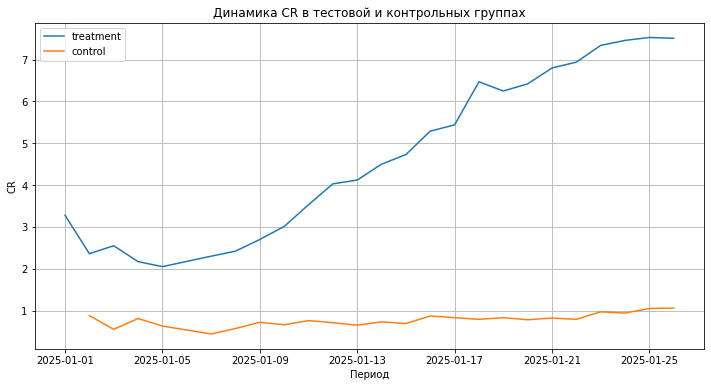

In [42]:
#Расчитаем кумулятивные метрики

#Приводим даты заказов и регистраций к формату дня
pa_marketplace_orders_AB['order_date'] = pd.to_datetime(pa_marketplace_orders_AB['order_date'])
pa_marketplace_users_AB['registration_date'] = pd.to_datetime(pa_marketplace_users_AB['registration_date'])
pa_marketplace_users_AB['day_active'] = pa_marketplace_users_AB['registration_date'].dt.date
pa_marketplace_orders_AB['day_active'] = pa_marketplace_orders_AB['order_date'].dt.date

#Считаем выручку маркетплейса
pa_marketplace_orders_AB['revenue'] = pa_marketplace_orders_AB['total_price'] * 0.05
   

#Объединяем покупки и регистрации со сплитом эксперимента
orders_with_groups = pd.merge(pa_marketplace_orders_AB, split_data_correct, how = 'inner', on = 'user_id') 
users_with_groups = pd.merge(pa_marketplace_users_AB, split_data_correct, how = 'inner', on = 'user_id') 
     
# Пустой список для результатов
records = []

#Создаем цикл для рассчета кумулятивных метрик
for current_date in sorted(orders_with_groups['day_active'].unique()):
    #Считаем выручку
    ord_to_date = orders_with_groups[orders_with_groups['day_active'] <= current_date]
    revenue = ord_to_date.groupby('group')['revenue'].sum().reset_index()
    
    #Считаем уникальных покупателей
    paid_users_count = ord_to_date.groupby('group')['user_id'].nunique().reset_index()
    paid_users_count = paid_users_count.rename(columns = {'user_id':'paid_users_count'})
    
    #Считаем количество заказов
    orders_count = ord_to_date.groupby('group')['order_id'].nunique().reset_index()
    orders_count = orders_count.rename(columns = {'order_id':'orders_count'})
    
    #Считаем количество пользователей
    user_to_date = users_with_groups[users_with_groups['day_active'] <= current_date]
    user_counts = user_to_date.groupby('group')['user_id'].nunique().reset_index()
    user_counts = user_counts.rename(columns = {'user_id':'user_counts'})
    
    #Создаем итоговую таблицу
    result = pd.merge(revenue, user_counts, on='group', how='inner')
    result = pd.merge(result, orders_count, on='group', how='inner')
    result = pd.merge(result, paid_users_count, on='group', how='inner')
    
    #Рассчитываем ключевую, вспомогательные и барьерную метрики
    result['arpu'] = (result['revenue'] / result['user_counts']).round(2)
    result['arppu'] = (result['revenue'] / result['paid_users_count']).round(2)
    result['cr'] = ((result['paid_users_count'] / result['user_counts']) * 100).round(2)
    result['aov'] = (result['revenue'] / result['orders_count']).round(2)
    result['date'] = current_date
     
    records.append(result)

#Обединяем все данные в одном датафрейме
arpu_df = pd.concat(records)

#Визуализируем динамику ключевой метрики
plt.figure(figsize=(12,6))

for group in arpu_df['group'].unique():
    df_plot = arpu_df[arpu_df['group'] == group]
    plt.plot(df_plot['date'], df_plot['cr'], label = group)

plt.title('Динамика CR в тестовой и контрольных группах')
plt.xlabel('Период')
plt.ylabel('CR')
plt.legend()
plt.grid()
plt.show()


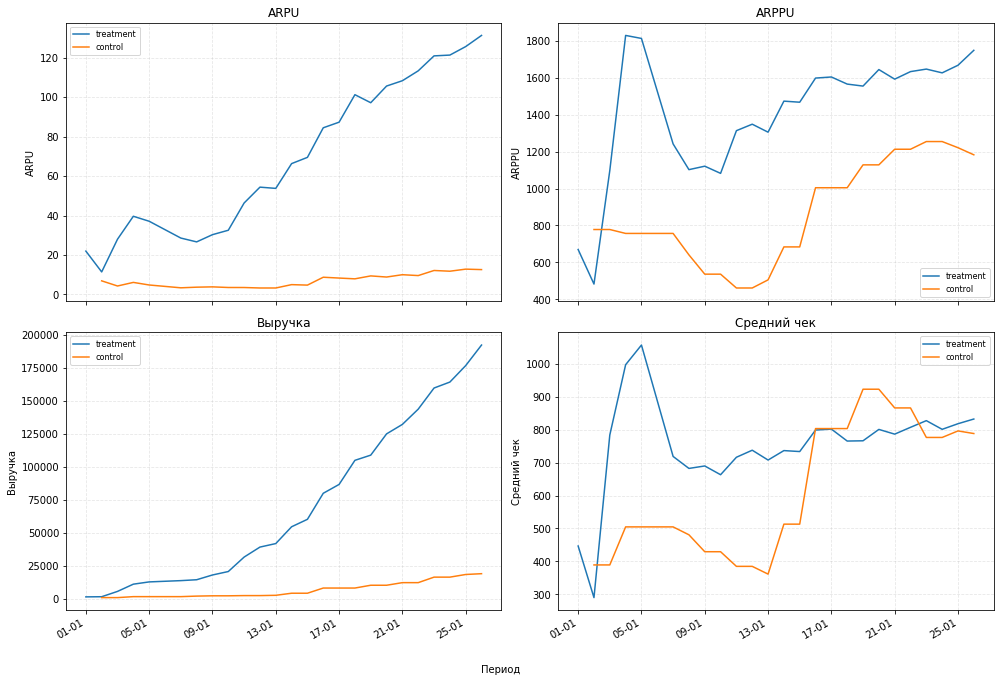

In [43]:

#Создаём фигуру и сетку
fig, axs = plt.subplots(2, 2, figsize=(14, 10), sharex=True)
axs = axs.flatten()

metrics = [
    ('arpu', 'ARPU'),
    ('arppu', 'ARPPU'),
    ('revenue', 'Выручка'),
    ('aov', 'Средний чек')
]

for ax, (col, title) in zip(axs, metrics):
    for group in arpu_df['group'].unique():
        df_plot = arpu_df[arpu_df['group'] == group]
        ax.plot(df_plot['date'], df_plot[col], label=group)
    
    ax.set_title(title)
    ax.set_ylabel(title)
    ax.legend(fontsize=8)
    ax.grid(True, linestyle='--', alpha=0.3)

# Общая подпись оси X
fig.text(0.5, 0.02, 'Период', ha='center')

# Форматирование дат на оси X (чтобы не наезжали)
plt.gcf().autofmt_xdate()
axs[0].xaxis.set_major_formatter(mdates.DateFormatter('%d-%m'))

plt.tight_layout(rect=[0, 0.05, 1, 0.96])  # оставляем место снизу для подписи X
plt.show()


In [45]:
# Объединение таблицы с событиями с данными о группах
data_exp_orders = pd.merge(pa_marketplace_orders_AB, split_data_correct[['user_id', 'group']], on = 'user_id', how='inner')
# Объединение таблицы с юзерами с данными о группах
data_exp_users = pd.merge(pa_marketplace_users_AB, split_data_correct[['user_id', 'group']], on = 'user_id', how='inner' )

#Проведем оценку предпосылки о достаточности данных для z-теста пропорций
n_a, n_b = data_exp_users[data_exp_users.group=='control'].shape[0], data_exp_users[data_exp_users.group=='treatment'].shape[0] ## размеры выборок A и B
m_a = data_exp_orders[data_exp_orders.group=='control']['user_id'].nunique() # количество успехов (покупок) в группе A
m_b = data_exp_orders[data_exp_orders.group=='treatment']['user_id'].nunique() # количество успехов (покупок) в группе B


p_a, p_b = m_a/n_a, m_b/n_b # рассчитываем доли успехов для каждой группы: A и B

print(f'n_a={n_a}, n_b={n_b}')

print(f'm_a={m_a}, m_b={m_b}')

print(f'p_a={p_a}, p_b={p_b}')

if (p_a*n_a > 10)and((1-p_a)*n_a > 10)and(p_b*n_b > 10)and((1-p_b)*n_b > 10):
    print('Предпосылка о достаточном количестве данных выполняется!')
else:
    print('Предпосылка о достаточном количестве данных НЕ выполняется!')


n_a=1503, n_b=1465
m_a=16, m_b=110
p_a=0.010645375914836993, p_b=0.07508532423208192
Предпосылка о достаточном количестве данных выполняется!


In [46]:
#Проведем тест
from statsmodels.stats.proportion import proportions_ztest

#Считаем выборку и количество покупок
reg_users = data_exp_users.groupby('group')['user_id'].nunique()
paid_users = data_exp_orders.groupby('group')['user_id'].nunique()

#Заводим переменные по группам
n_control = reg_users['control']
n_test = reg_users['treatment']
m_control = paid_users['control']
m_test = paid_users['treatment']

#Считаем конверсию
cr_control = m_control / n_control
cr_test =  m_test / n_test

#Считаем относительную и абсолютные разницы
abs_diff = cr_test - cr_control
rel_diff = (cr_test / cr_control) - 1

#Проводим z-тест пропорций с уровнем значимости 0.05
#H0:Конверсия в покупку в тестовой группе и контрольной группе не отличаются
#H1:Конверсия в покупку в тестовой группе выше, чем в контрольной
alpha = 0.05
stat, p_value = proportions_ztest ([m_control, m_test], [n_control, n_test], alternative='smaller')


results_key = pd.DataFrame([{'Group_A': 'control', 'Group_B': 'test',
                            'CR_A, %': round(cr_control * 100.0, 2), 
                             'CR_B, %': round(cr_test * 100.0, 2),
                            'p_value': p_value,
                            'Absolute Lift, п.п': round(abs_diff * 100.0, 2),
                            'Relative Lift, %': round(rel_diff * 100.0, 2)}])

display(results_key)

if p_value > alpha:
    print(f'pvalue={p_value} > {alpha}')
    print('Нулевая гипотеза находит подтверждение!')
else:
    print(f'pvalue={p_value} < {alpha}')
    print('Нулевая гипотеза не находит подтверждения!')


,Group_A,Group_B,"CR_A, %","CR_B, %",p_value,"Absolute Lift, п.п","Relative Lift, %"
0,control,test,1.06,7.51,1.582453e-18,6.44,605.33


pvalue=1.582452894902882e-18 < 0.05
Нулевая гипотеза не находит подтверждения!


In [47]:
#Посчитаем приросты по вспомогательным и барьерной метрикам

#Пустой список для результатов
records_total = []

#Выручка
revenue = orders_with_groups.groupby('group')['revenue'].sum().reset_index()

#Количество покупателей
paid_users_count = orders_with_groups.groupby('group')['user_id'].nunique().reset_index()
paid_users_count = paid_users_count.rename(columns = {'user_id':'paid_users_count'})
    
#Считаем количество заказов
orders_count = orders_with_groups.groupby('group')['order_id'].nunique().reset_index()
orders_count = orders_count.rename(columns = {'order_id':'orders_count'})
    
#Считаем количество пользователей
user_counts = users_with_groups.groupby('group')['user_id'].nunique().reset_index()
user_counts = user_counts.rename(columns = {'user_id':'user_counts'})
    
#Создаем итоговую таблицу
result = pd.merge(revenue, user_counts, on='group', how='inner')
result = pd.merge(result, orders_count, on='group', how='inner')
result = pd.merge(result, paid_users_count, on='group', how='inner')
    
#Рассчитываем вспомогательные и барьерную метрики
result['arpu'] = (result['revenue'] / result['user_counts']).round(2)
result['arppu'] = (result['revenue'] / result['paid_users_count']).round(2)
result['cr'] = ((result['paid_users_count'] / result['user_counts']) * 100).round(2)
result['aov'] = (result['revenue'] / result['orders_count']).round(2)
     
records_total.append(result)

#Обединяем все данные в одном датафрейме
arpu_df_total = pd.concat(records_total)

#Создаем переменные с итоговыми метриками по группам
control = arpu_df_total[arpu_df_total['group'] == 'control'].iloc[0]
treatment = arpu_df_total[arpu_df_total['group'] == 'treatment'].iloc[0]

#Создаем датафрейм для сравнения
metrics_comparison = pd.DataFrame({
    'Метрика': ['ARPU, руб.', 'ARPPU, руб.', 'AOV, руб.', 'Выручка общая, руб.'],
    'Контроль (A)': [
        round(control['arpu'], 2),
        round(control['arppu'], 2),
        round(control['aov'], 2),
        round(control['revenue'], 2)
    ],
    'Тест (B)': [
        round(treatment['arpu'], 2),
        round(treatment['arppu'], 2),
        round(treatment['aov'], 2),
        round(treatment['revenue'], 2)
    ]
})

#Добавляем столбцы с разницей и лифтом
metrics_comparison['Absolute Lift'] = metrics_comparison['Тест (B)'] - metrics_comparison['Контроль (A)']
metrics_comparison['Relative Lift, %'] = ((metrics_comparison['Тест (B)'] - metrics_comparison['Контроль (A)']) / 
                               metrics_comparison['Контроль (A)'] * 100).round(2)

metrics_comparison


,Метрика,Контроль (A),Тест (B),Absolute Lift,"Relative Lift, %"
0,"ARPU, руб.",12.59,131.25,118.66,942.49
1,"ARPPU, руб.",1182.42,1748.00,565.58,47.83
2,"AOV, руб.",788.28,832.38,44.10,5.59
3,"Выручка общая, руб.",18918.64,192279.85,173361.21,916.35


Перед проведением теста посмотрим на динамику пользователей и покупок в группах


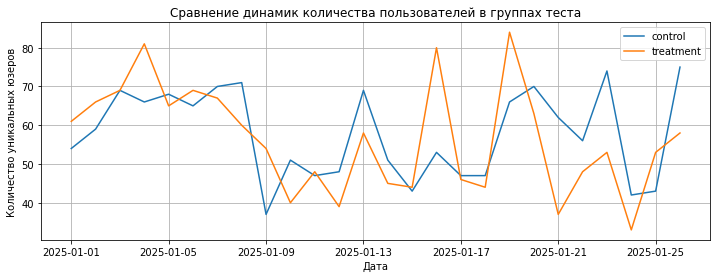

In [48]:
#Посмотрим динамику количества пользователей по группам эксперимента
df_grp = data_exp_users.groupby(['group', 'day_active']).agg({'user_id':'nunique'}).reset_index()
x = df_grp['day_active'].unique()
y_a = df_grp[df_grp['group'] == 'control']['user_id']
y_b = df_grp[df_grp['group'] == 'treatment']['user_id']

plt.figure(figsize=(12, 4))
plt.plot(x, y_a, label ='control')
plt.plot(x, y_b, label ='treatment')

plt.xlabel("Дата")
plt.ylabel("Количество уникальных юзеров")
plt.legend()
plt.grid()
plt.title('Сравнение динамик количества пользователей в группах теста')
plt.show()


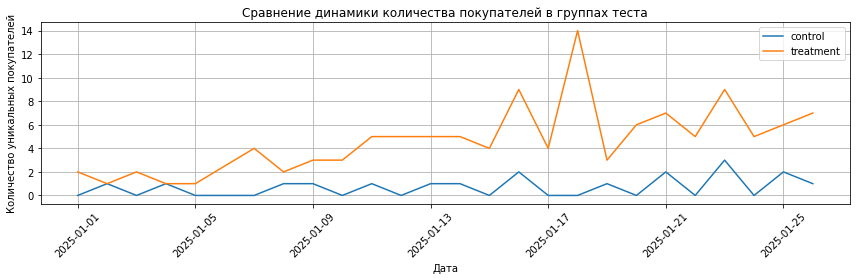

In [49]:
#Посмотрим динамику количества покупателей по группам эксперимента
df_grp_buyers = data_exp_orders.groupby(['group', 'day_active']).agg({'user_id':'nunique'}).reset_index()

#Преобразуем в сводную таблицу
buyers_pivot = df_grp_buyers.pivot_table(
    index='day_active', 
    columns='group', 
    values='user_id', 
    fill_value=0
).reset_index()

plt.figure(figsize=(12, 4))
plt.plot(buyers_pivot['day_active'], buyers_pivot['control'], label='control')
plt.plot(buyers_pivot['day_active'], buyers_pivot['treatment'], label='treatment')

plt.xlabel("Дата")
plt.ylabel("Количество уникальных покупателей")
plt.legend()
plt.title('Сравнение динамики количества покупателей в группах теста')
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid()
plt.show()


Общее количество пользователей было примерно равным в группах эксперимента. А дневной количество покупателей в тестовой группе было заметно выше, чем в контрольной. Это нужно учесть при подборе методики расчета pvalue.


Для ARPPU использую бутстрэп, так как количество платящих пользователей существенно различается между группами, и стандартный t-тест не учитывает это различие. Для ARPU применен t-тест, поскольку размеры групп сбалансированы, и это допустимое упрощение


In [50]:
from scipy import stats
#Проведем t-тест для метрики ARPU. Учитывая, что в среднем размер выборок идентичен, он нам подходит для задач
#H0: ARPU равен с тестовой и контрольной группах
#H1: ARPU в тестовой группе выше, чем в контрольной

revenue_by_user = orders_with_groups.groupby(['user_id','group'])['revenue'].sum().reset_index()
total_users = users_with_groups[['user_id','group']].drop_duplicates()

users_revenue = pd.merge(total_users, revenue_by_user, on=['user_id', 'group'], how='left')
users_revenue['revenue'] = users_revenue['revenue'].fillna(0)

arpu_control = users_revenue[users_revenue['group'] == 'control']['revenue']
arpu_test = users_revenue[users_revenue['group'] == 'treatment']['revenue']

# T-тест для ARPU
alpha = 0.05
t_stat, p_value = stats.ttest_ind(arpu_test, arpu_control, alternative='greater')
print(f'ARPU t-test: t-statistic={t_stat:.4f}, p-value={p_value:.10f}')

if p_value > alpha:
    print(f'pvalue={p_value:.10f} > {alpha}')
    print('Нулевая гипотеза находит подтверждение!')
else:
    print(f'pvalue={p_value} < {alpha}')
    print('Нулевая гипотеза не находит подтверждения!')


ARPU t-test: t-statistic=5.9848, p-value=0.0000000012
pvalue=1.2129077206757173e-09 < 0.05
Нулевая гипотеза не находит подтверждения!


In [51]:
import numpy as np
#Проведем t-тест для метрики ARPPU. Учитывая, что в среднем размер выборки выше в тестовой группе, используем бутстрап
#H0: ARPPU равен с тестовой и контрольной группах
#H1: ARPPU в тестовой группе выше, чем в контрольной
def bootstrap_arppu(orders_df, n_iterations=10000):
    control = orders_df[orders_df['group'] == 'control']
    test = orders_df[orders_df['group'] == 'treatment']
    
    control_users = control['user_id'].unique()
    test_users = test['user_id'].unique()
    
    arppu_diffs = []
    
    for _ in range(n_iterations):
        # Сэмплируем пользователей с повторениями
        control_sample_users = np.random.choice(control_users, size=len(control_users), replace=True)
        test_sample_users = np.random.choice(test_users, size=len(test_users), replace=True)
        
        # Считаем ARPPU для каждой выборки
        control_revenue = control[control['user_id'].isin(control_sample_users)]['revenue'].sum()
        test_revenue = test[test['user_id'].isin(test_sample_users)]['revenue'].sum()
        
        control_arppu = control_revenue / len(control_sample_users)
        test_arppu = test_revenue / len(test_sample_users)
        
        arppu_diffs.append(test_arppu - control_arppu)
    
    p_value = (np.array(arppu_diffs) <= 0).mean()
    return np.mean(arppu_diffs), p_value

diff_mean, p_value = bootstrap_arppu(orders_with_groups)
alpha = 0.05
print(f'ARPPU bootstrap: diff={diff_mean:.2f}, p-value={p_value:.4f}')
if p_value > alpha:
    print(f'pvalue={p_value:.10f} > {alpha}')
    print('Нулевая гипотеза находит подтверждение!')
else:
    print(f'pvalue={p_value} < {alpha}')
    print('Нулевая гипотеза не находит подтверждения!')


ARPPU bootstrap: diff=346.72, p-value=0.0200
pvalue=0.02 < 0.05
Нулевая гипотеза не находит подтверждения!


In [52]:
#Проведем t-тест для среднего чека
#H0: Средние чеки равные с тестовой и контрольной группах
#H1: Средний чек в тестовой группе выше, чем в контрольной
orders_aov = orders_with_groups[['order_id', 'group', 'revenue']].drop_duplicates()
aov_control = orders_aov[orders_aov['group'] == 'control']['revenue']
aov_test = orders_aov[orders_aov['group'] == 'treatment']['revenue']

t_stat, p_value = stats.ttest_ind(aov_test, aov_control, alternative='greater')
print(f'AOV t-test: p-value = {p_value:.4f}')
if p_value > alpha:
    print(f'pvalue={p_value:.10f} > {alpha}')
    print('Нулевая гипотеза находит подтверждение!')
else:
    print(f'pvalue={p_value} < {alpha}')
    print('Нулевая гипотеза не находит подтверждения!')


AOV t-test: p-value = 0.4261
pvalue=0.4260840480 > 0.05
Нулевая гипотеза находит подтверждение!


## Выводы по этапу 5


Представьте ключевые выводы в текстовом виде здесь или приложите ссылку на документ с презентацией.

Не забудьте предоставить доступ на просмотр и комментирование документа.


Эксперимент можно считать успешным. После внедрения бонуса на первую покупку для аудитория тик-тока, конверсия в первую покупку в тестовой группе статистически значимо улучшилась относительно контрольной группы. Барьерные и вспомогательные метрики не показали серьёзных отклонений в тестовых группах и все показали положительные приросты относительно контроля. Метрики ARPU и ARPPU значимо выше в тестовой группе, на 945% и 48% соответственно.


Внедрение бонуса за первую покупку положительно повлияло на прирост выручки по тестовой аудитории. Пользователи в тестовой группе нагенерили нам в 9 раз больше выручку, чем те, кому мы не давали бонус на первую покупку. И рост выручку существенно повлияло на улучшение метрик средней выручки на пользователя и на покупателя.


### Проблемы эксперимента
1. Отсутсвие MDE не позволило нам рассчитать целевой объем аудитории и период. Так как есть явный эффект, это не критично, но в дальнейшем желательно оценивать ожидаемый эффект
2. Бонус на первую покупку достаточно весомый стимул для покупки. В качестве одной из барьерных метрик можно было оценить динамику ROI и удержания, чтобы понять не повлияло ли это на окупаемость и возращаемость
3. Эксперимент пришелся на праздничные дни, что также могло оказывать влияние на поведение аудитории
4. Небольшое количество покупателей в контрольной группе могло существенно влиять на колебания метрики. Поэтому можно либо продлить эксперимент, либо выбирать метрику с более стабильным поведением
5. Сложно понять как масштабировать бонус на другие каналы и нет ли канибализации других каналов.


### Рекомендации
1. Рекомендуем оценить как новая активность повлияла на юнит-экономику и был ли инкрементальный прирост выручки
2. Если есть положительный прирост, то фичу можно расскатить на всех пользователей ТикТока
3. Мониторить влияние на LTV и ретеншн у пользователей, которых коснулось предложение, чтобы оценить долгосрочный эффект
